<div align="center">

# Universidad Autónoma de Chihuahua
## Facultad de Ingeniería
### Maestría en Ingeniería en Computación

**Materia:** Machine Learning (MIC1)

**Actividad:** Proyecto Final — Notebook 3: Modelos y optimización de hiperparámetros

**Alumno:** Jonahtan Gabriel González Cardoza
**Matrícula:** 345491

**Catedrática:** Dra. Olanda Prieto Ordaz

**Fecha de elaboración:** 21 de noviembre de 2026

</div>

**Proyecto:** predicción de la situación final de un estudiante (*Dropout*, *Enrolled*, *Graduate*) con el dataset
*Predict Students' Dropout and Academic Success* (UCI 697). Este proyecto reúne, en cinco notebooks reproducibles, el trabajo
de las tres prácticas anteriores (regresión logística del Proyecto F_1, SVM y métodos de ensamble).

**Objetivo de este notebook.** Evaluar con **validación cruzada de 5 folds sobre Train** (mismos folds para todos los modelos): modelos de referencia (regresión logística y SVM), ensambles con hiperparámetros base, y los mismos ensambles tras optimizar sus hiperparámetros. **Test no se carga en este notebook.** Al final guarda los modelos, las predicciones *out-of-fold* y las búsquedas para el notebook 04.

# III. Desarrollo (continuación)

In [1]:
from config import *

# Test NO se carga en este notebook: la selección de modelos usa solo Train
X_train, _, y_train, _ = cargar_particion()
numeric_cols, nominal_cols, binary_cols = columnas()
reg = Registro(X_train, y_train)

# Alias: el resto del notebook usa los mismos nombres que la práctica de ensambles
resultados_cv, oof, modelos_ajustados = reg.resultados_cv, reg.oof, reg.modelos_ajustados
searches, tiempos_busqueda = reg.searches, reg.tiempos_busqueda
evaluar_cv, tabla_resumen, tabla_por_clase = reg.evaluar_cv, reg.tabla_resumen, reg.tabla_por_clase
comparar_oob, oob_res = reg.comparar_oob, reg.oob_res
buscar = reg.buscar
print(f"Train: {X_train.shape[0]:,} estudiantes × {X_train.shape[1]} características")

Train: 3,539 estudiantes × 36 características


### 8. ¿Hace falta una submuestra de Train?
Con un dataset de cientos de miles de instancias, los modelos de costo cuadrático o cúbico (como un `SVC` con kernel) solo pueden optimizarse sobre una **submuestra estratificada**. Aquí Train tiene 3,539 estudiantes, y el costo de los ensambles crece aproximadamente de forma lineal con el número de estudiantes y con el de árboles. Se mide en las secciones siguientes (columna "Ajuste con todo Train (s)"): cada modelo tarda de menos de un segundo a ≈1 min en ajustarse (el *Stacking*, que entrena sus modelos base una vez por fold interno, es el más lento).

**No se submuestrea:** la validación cruzada, las búsquedas y los modelos finales usan todo Train, igual que la regresión logística del Proyecto F_1 y que el SVM de la práctica anterior. Con 635 *Enrolled* en Train, una submuestra solo quitaría información justo de la clase difícil. Test se usa completo y una sola vez, al final.

## Fase 5. Experimentación con ensambles

### 9. Configuración común
Todos los modelos se evalúan con el **mismo** `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` del Proyecto F_1, así que los folds son idénticos y los números de la regresión logística y del SVM se reproducen. Para cada modelo se registran media ± desviación de cada métrica, el score en los folds de entrenamiento (para medir el *gap*), las predicciones *out-of-fold* (OOF), el número de estimadores y los tiempos.

**Se reportan todas las métricas, no solo las favorables.** Varios trabajos publicados con este dataset reportan una sola métrica, sin el protocolo de partición o solo por clase (ver Fase 11), lo que impide saber si un resultado es bueno o solo está bien presentado. Aquí se reporta siempre el conjunto completo:

| Métrica | Qué mide con 3 clases |
|---|---|
| Accuracy | Proporción de estudiantes en su clase correcta. Engañosa con desbalance (el Dummy logra 0.4993) |
| Precision, Recall, F1 (**macro**) | Promedio sin ponderar de la métrica de cada clase; *Enrolled* pesa igual que *Graduate*. El Recall macro es la *balanced accuracy* |
| F1 **ponderado** | Promedio de los F1 por clase ponderado por su frecuencia (el "F1 global" de Martins et al., 2023). Favorece a la clase mayoritaria |
| MCC (Matthews) | Correlación entre clase real y predicha usando toda la matriz de confusión; 0 = azar, 1 = perfecto. Es robusto al desbalance |
| Kappa de Cohen | Acuerdo entre real y predicha descontando el acuerdo esperado por azar |
| ROC-AUC (**OvR macro**) | Un AUC por clase (esa clase contra el resto), promediado. Mide el **ordenamiento**, sin depender de la regla de decisión |
| Por clase | Precision, Recall, F1 y AUC de cada clase (OOF) |

> **ROC-AUC según el modelo.** Los ensambles con probabilidades (todos menos el *Voting hard*) usan `predict_proba`. El *Voting hard* vota por clase y no produce un puntaje continuo, así que su ROC-AUC no existe ("—" en las tablas). `SVC` solo ofrece `decision_function`, que con 3 clases resume votos uno contra uno; esa diferencia se analiza en la Sección 26. Dentro del *Voting soft* y del *Stacking* el SVM se calibra con `CalibratedClassifierCV` (sigmoide), que sí da probabilidades.

In [2]:
# El CV (StratifiedKFold de 5 folds, shuffle, random_state=42), las 8 métricas, evaluar_cv(), tabla_resumen(), etc. están en config.py
print("Validación cruzada:", cv)
print("Métricas registradas:", METRICAS)
print(f"Train: {X_train.shape[0]:,} estudiantes (Test no se carga en este notebook)")

Validación cruzada: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Métricas registradas: ['Accuracy', 'Precision', 'Recall', 'F1', 'F1 ponderado', 'MCC', 'Kappa', 'ROC-AUC']
Train: 3,539 estudiantes (Test no se carga en este notebook)


### 9.1 Acumulado de los mejores modelos (referencias)
De las prácticas anteriores se conservan, **sin repetir sus entrenamientos ni sus búsquedas**, solo los mejores modelos, con sus hiperparámetros fijos:

- `DummyClassifier(strategy="most_frequent")`: piso mínimo (siempre predice *Graduate*).
- **Regresión logística del Proyecto F_1**: `C = 0.3`, penalización L1 (solver `saga`) y `class_weight = "balanced"`. Su regla de decisión oficial es *Dropout* si P(*Dropout*) ≥ 0.40 (se aplica solo en Test, Sección 24; en CV se usa la regla por defecto, la clase de mayor probabilidad).
- **El mejor SVM de cada kernel** (práctica de SVM): lineal (`LinearSVC`, `C = 0.01`, `class_weight = "balanced"`), polinomial (`degree = 2`, `coef0 = 1`, `C = 1`, `class_weight = "balanced"`) y RBF (`C = 100`, `gamma = 0.001`, sin pesos; el SVM final de esa práctica).

Se descartan los SVM con parámetros por defecto y las mallas de búsqueda de los SVM. Los modelos de referencia se vuelven a evaluar aquí con exactamente los mismos folds, para compararlos con los ensambles con la misma vara.

In [3]:
# BEST_LR, BEST_SVM, NOMBRE_LR y predecir_regla() están en config.py (hiperparámetros fijos; NO se repiten sus búsquedas)

modelos_ref = {
    "Dummy (referencia)": Pipeline([("model", DummyClassifier(strategy="most_frequent"))]),
    NOMBRE_LR: crear_pipeline(LogisticRegression(**BEST_LR, max_iter=5000, random_state=RANDOM_STATE)),
    **{n: crear_pipeline(d["modelo"](**d["params"])) for n, d in BEST_SVM.items()},
}
for nombre, pipe in modelos_ref.items():
    evaluar_cv(nombre, pipe)

# Modelos BASE de referencia: LR y SVM con los hiperparámetros por defecto de scikit-learn (para la comparación base vs. optimizado)
modelos_defecto = {
    "Regresión Logística base (por defecto)": crear_pipeline(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    "SVM Lineal (por defecto)": crear_pipeline(LinearSVC(max_iter=10_000, random_state=RANDOM_STATE)),
    "SVM Polinomial (por defecto)": crear_pipeline(SVC(kernel="poly", cache_size=1000)),
    "SVM RBF (por defecto)": crear_pipeline(SVC(kernel="rbf", cache_size=1000)),
}
for nombre, pipe in modelos_defecto.items():
    evaluar_cv(nombre, pipe)

Dummy (referencia):  Accuracy=0.4993±0.0006  Recall=0.3333±0.0000  F1=0.2220±0.0002  MCC=0.0000±0.0000  ROC-AUC=0.5000±0.0000  | gap F1=0.000 | CV 0.8s, ajuste 0.0s


Regresión Logística (F_1):  Accuracy=0.7584±0.0147  Recall=0.7243±0.0210  F1=0.7170±0.0192  MCC=0.6178±0.0227  ROC-AUC=0.8913±0.0104  | gap F1=0.033 | CV 3.0s, ajuste 2.4s


SVM Lineal optimizado:  Accuracy=0.7717±0.0118  Recall=0.6998±0.0172  F1=0.7086±0.0187  MCC=0.6233±0.0199  ROC-AUC=0.8742±0.0104  | gap F1=0.024 | CV 0.8s, ajuste 0.0s


SVM Polinomial optimizado:  Accuracy=0.7615±0.0095  Recall=0.7283±0.0137  F1=0.7211±0.0115  MCC=0.6220±0.0141  ROC-AUC=0.8739±0.0094  | gap F1=0.103 | CV 1.1s, ajuste 0.2s


SVM RBF optimizado:  Accuracy=0.7872±0.0059  Recall=0.7092±0.0102  F1=0.7217±0.0108  MCC=0.6483±0.0105  ROC-AUC=0.8630±0.0090  | gap F1=0.043 | CV 0.5s, ajuste 0.2s


Regresión Logística base (por defecto):  Accuracy=0.7762±0.0117  Recall=0.6909±0.0171  F1=0.7006±0.0191  MCC=0.6288±0.0199  ROC-AUC=0.8895±0.0086  | gap F1=0.039 | CV 0.1s, ajuste 0.0s


SVM Lineal (por defecto):  Accuracy=0.7725±0.0097  Recall=0.6717±0.0142  F1=0.6806±0.0172  MCC=0.6225±0.0167  ROC-AUC=0.8721±0.0102  | gap F1=0.038 | CV 0.1s, ajuste 0.1s


SVM Polinomial (por defecto):  Accuracy=0.7525±0.0130  Recall=0.6505±0.0166  F1=0.6637±0.0200  MCC=0.5897±0.0235  ROC-AUC=0.8498±0.0103  | gap F1=0.137 | CV 0.5s, ajuste 0.2s


SVM RBF (por defecto):  Accuracy=0.7725±0.0153  Recall=0.6790±0.0218  F1=0.6909±0.0250  MCC=0.6225±0.0269  ROC-AUC=0.8608±0.0082  | gap F1=0.103 | CV 0.6s, ajuste 0.2s


In [4]:
display(tabla_resumen())
print("Recall por clase (OOF):")
display(tabla_por_clase("Recall").round(4))
print("F1 por clase (OOF):")
display(tabla_por_clase("F1").round(4))
guardar_tabla(tabla_resumen(), "03_referencias_cv")

,Accuracy,Precision,Recall,F1,F1 ponderado,MCC,Kappa,ROC-AUC,Gap F1 (train−CV),Estimadores,Nº SV,Ajuste con todo Train (s)
Dummy (referencia),0.4993 ± 0.0006,0.1664 ± 0.0002,0.3333 ± 0.0000,0.2220 ± 0.0002,0.3325 ± 0.0007,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.0000,—,—,0.01
Regresión Logística (F_1),0.7584 ± 0.0147,0.7203 ± 0.0201,0.7243 ± 0.0210,0.7170 ± 0.0192,0.7663 ± 0.0136,0.6178 ± 0.0227,0.6146 ± 0.0224,0.8913 ± 0.0104,0.0328,—,—,2.44
SVM Lineal optimizado,0.7717 ± 0.0118,0.7249 ± 0.0223,0.6998 ± 0.0172,0.7086 ± 0.0187,0.7654 ± 0.0130,0.6233 ± 0.0199,0.6198 ± 0.0193,0.8742 ± 0.0104,0.0238,—,—,0.03
SVM Polinomial optimizado,0.7615 ± 0.0095,0.7248 ± 0.0135,0.7283 ± 0.0137,0.7211 ± 0.0115,0.7687 ± 0.0088,0.6220 ± 0.0141,0.6189 ± 0.0138,0.8739 ± 0.0094,0.1030,—,"2,022",0.19
SVM RBF optimizado,0.7872 ± 0.0059,0.7496 ± 0.0142,0.7092 ± 0.0102,0.7217 ± 0.0108,0.7773 ± 0.0080,0.6483 ± 0.0105,0.6419 ± 0.0105,0.8630 ± 0.0090,0.0432,—,"1,636",0.18
Regresión Logística base (por defecto),0.7762 ± 0.0117,0.7274 ± 0.0214,0.6909 ± 0.0171,0.7006 ± 0.0191,0.7635 ± 0.0132,0.6288 ± 0.0199,0.6230 ± 0.0193,0.8895 ± 0.0086,0.0390,—,—,0.04
SVM Lineal (por defecto),0.7725 ± 0.0097,0.7289 ± 0.0235,0.6717 ± 0.0142,0.6806 ± 0.0172,0.7519 ± 0.0115,0.6225 ± 0.0167,0.6110 ± 0.0163,0.8721 ± 0.0102,0.0380,—,—,0.06
SVM Polinomial (por defecto),0.7525 ± 0.0130,0.7154 ± 0.0220,0.6505 ± 0.0166,0.6637 ± 0.0200,0.7323 ± 0.0151,0.5897 ± 0.0235,0.5727 ± 0.0227,0.8498 ± 0.0103,0.1372,—,"2,158",0.21
SVM RBF (por defecto),0.7725 ± 0.0153,0.7306 ± 0.0239,0.6790 ± 0.0218,0.6909 ± 0.0250,0.7561 ± 0.0188,0.6225 ± 0.0269,0.6121 ± 0.0273,0.8608 ± 0.0082,0.1031,—,"2,004",0.19


Recall por clase (OOF):


,Dropout,Enrolled,Graduate
Dummy (referencia),0.0000,0.0000,1.0000
Regresión Logística (F_1),0.7361,0.6110,0.8257
SVM Lineal optimizado,0.7502,0.4472,0.9021
SVM Polinomial optimizado,0.7353,0.6205,0.8291
SVM RBF optimizado,0.7617,0.4362,0.9298
Regresión Logística base (por defecto),0.7713,0.3795,0.9219
SVM Lineal (por defecto),0.7722,0.3008,0.9423
SVM Polinomial (por defecto),0.6948,0.3071,0.9496
SVM RBF (por defecto),0.7537,0.3449,0.9383


F1 por clase (OOF):


,Dropout,Enrolled,Graduate
Dummy (referencia),0.0000,0.0000,0.6660
Regresión Logística (F_1),0.7833,0.5265,0.8416
SVM Lineal optimizado,0.7884,0.4867,0.8508
SVM Polinomial optimizado,0.7868,0.5368,0.8407
SVM RBF optimizado,0.7982,0.5059,0.8618
Regresión Logística base (por defecto),0.7894,0.4551,0.8580
SVM Lineal (por defecto),0.7892,0.3983,0.8552
SVM Polinomial (por defecto),0.7614,0.3967,0.8348
SVM RBF (por defecto),0.7902,0.4337,0.8505


,Accuracy,Precision,Recall,F1,F1 ponderado,MCC,Kappa,ROC-AUC,Gap F1 (train−CV),Estimadores,Nº SV,Ajuste con todo Train (s)
Dummy (referencia),0.4993 ± 0.0006,0.1664 ± 0.0002,0.3333 ± 0.0000,0.2220 ± 0.0002,0.3325 ± 0.0007,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.0000,—,—,0.01
Regresión Logística (F_1),0.7584 ± 0.0147,0.7203 ± 0.0201,0.7243 ± 0.0210,0.7170 ± 0.0192,0.7663 ± 0.0136,0.6178 ± 0.0227,0.6146 ± 0.0224,0.8913 ± 0.0104,0.0328,—,—,2.44
SVM Lineal optimizado,0.7717 ± 0.0118,0.7249 ± 0.0223,0.6998 ± 0.0172,0.7086 ± 0.0187,0.7654 ± 0.0130,0.6233 ± 0.0199,0.6198 ± 0.0193,0.8742 ± 0.0104,0.0238,—,—,0.03
SVM Polinomial optimizado,0.7615 ± 0.0095,0.7248 ± 0.0135,0.7283 ± 0.0137,0.7211 ± 0.0115,0.7687 ± 0.0088,0.6220 ± 0.0141,0.6189 ± 0.0138,0.8739 ± 0.0094,0.1030,—,"2,022",0.19
SVM RBF optimizado,0.7872 ± 0.0059,0.7496 ± 0.0142,0.7092 ± 0.0102,0.7217 ± 0.0108,0.7773 ± 0.0080,0.6483 ± 0.0105,0.6419 ± 0.0105,0.8630 ± 0.0090,0.0432,—,"1,636",0.18
Regresión Logística base (por defecto),0.7762 ± 0.0117,0.7274 ± 0.0214,0.6909 ± 0.0171,0.7006 ± 0.0191,0.7635 ± 0.0132,0.6288 ± 0.0199,0.6230 ± 0.0193,0.8895 ± 0.0086,0.0390,—,—,0.04
SVM Lineal (por defecto),0.7725 ± 0.0097,0.7289 ± 0.0235,0.6717 ± 0.0142,0.6806 ± 0.0172,0.7519 ± 0.0115,0.6225 ± 0.0167,0.6110 ± 0.0163,0.8721 ± 0.0102,0.0380,—,—,0.06
SVM Polinomial (por defecto),0.7525 ± 0.0130,0.7154 ± 0.0220,0.6505 ± 0.0166,0.6637 ± 0.0200,0.7323 ± 0.0151,0.5897 ± 0.0235,0.5727 ± 0.0227,0.8498 ± 0.0103,0.1372,—,"2,158",0.21
SVM RBF (por defecto),0.7725 ± 0.0153,0.7306 ± 0.0239,0.6790 ± 0.0218,0.6909 ± 0.0250,0.7561 ± 0.0188,0.6225 ± 0.0269,0.6121 ± 0.0273,0.8608 ± 0.0082,0.1031,—,"2,004",0.19


**Interpretación.**
- **Los modelos de referencia reproducen exactamente sus resultados anteriores** (mismos folds): regresión logística F1 macro 0.7170 ± 0.0192 y ROC-AUC 0.8913 ± 0.0104 (Proyecto F_1); SVM lineal 0.7086, polinomial 0.7211 y RBF 0.7217 (práctica de SVM). Aquí se reportan además F1 ponderado, MCC y Kappa: para la regresión logística 0.7663, 0.6178 y 0.6146.
- **El Dummy marca el piso:** Accuracy 0.4993, F1 macro 0.2220, MCC y Kappa iguales a 0 (no es mejor que el azar) y ROC-AUC 0.5. Su F1 ponderado (0.3325) es mayor que su F1 macro: premia acertar la clase mayoritaria, por eso no basta para evaluar este problema.
- **Las referencias están en un mismo rango de F1 macro (0.7086–0.7217)**, pero tienen perfiles distintos. El SVM RBF tiene el mayor Accuracy (0.7872) y MCC (0.6483), y reconoce a 93.0% de los *Graduate* pero a solo 43.6% de los *Enrolled* (Recall OOF); la regresión logística y el SVM polinomial, que están ponderados, reconocen a 61.1% y 62.1% de los *Enrolled* y a 82.6% y 82.9% de los *Graduate*.
- **El gap train − CV es pequeño** en la regresión logística (0.033), el SVM lineal (0.024) y el RBF (0.043); el polinomial sobreajusta más (0.103).
- El ROC-AUC del SVM (0.8630 y 0.8742 en los otros kernels) se calcula con `decision_function` y no es comparable con el de los modelos con probabilidades (Sección 26).

### 9.2 Regla de decisión de la regresión logística (Proyecto F_1)
La regresión logística se evalúa con dos reglas: la clase más probable (por defecto) y la regla de alerta temprana *Dropout si P(Dropout) ≥ t*. El threshold `t`
se elige aquí con las predicciones *out-of-fold* de Train, con el criterio declarado de antemano en el Proyecto F_1 (mayor F1 macro; si varias quedan a menos de
0.005, la de mayor Recall de *Dropout*). Test no interviene en esta decisión.

,Precision (Dropout),Recall (Dropout),F1 (Dropout),Recall (Enrolled),F1 macro,Accuracy,Falsos positivos (Dropout),Falsos negativos (Dropout)
Regla,,,,,,,,
Clase más probable,0.8370,0.7361,0.7833,0.6110,0.7171,0.7584,163,300
P(Dropout) ≥ 0.30,0.7639,0.8197,0.7908,0.4929,0.7058,0.7593,288,205
P(Dropout) ≥ 0.40,0.8303,0.7573,0.7921,0.5748,0.7149,0.7595,176,276
P(Dropout) ≥ 0.50,0.8697,0.7045,0.7784,0.6283,0.7148,0.7550,120,336
P(Dropout) ≥ 0.60,0.9115,0.6614,0.7666,0.6724,0.7141,0.7516,73,385
P(Dropout) ≥ 0.70,0.9379,0.5981,0.7304,0.6945,0.6980,0.7364,45,457


Regla seleccionada con OOF de Train: P(Dropout) ≥ 0.40 | en el Proyecto F_1 se había fijado P(Dropout) ≥ 0.40


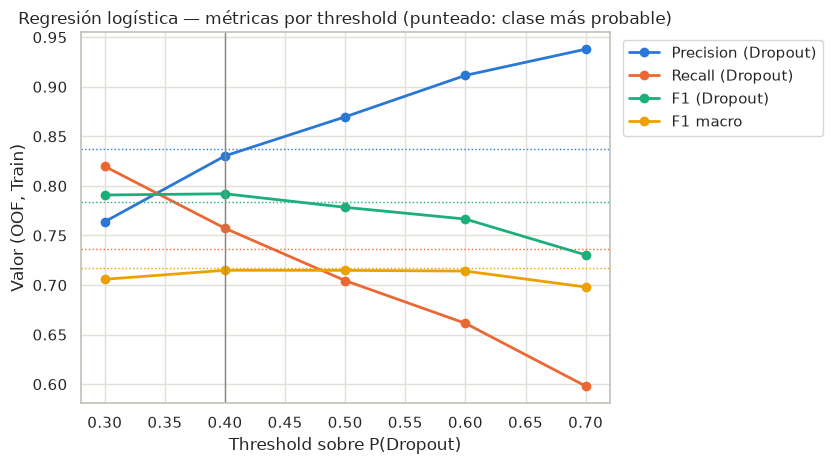

,umbral,Precision (Dropout),Recall (Dropout),F1 (Dropout),Recall (Enrolled),F1 macro,Accuracy,Falsos positivos (Dropout),Falsos negativos (Dropout)
Regla,,,,,,,,,
Clase más probable,NaN,0.837000,0.736148,0.783341,0.611024,0.717150,0.758406,163,300
P(Dropout) ≥ 0.30,0.3,0.763934,0.819701,0.790836,0.492913,0.705826,0.759254,288,205
P(Dropout) ≥ 0.40,0.4,0.830280,0.757256,0.792088,0.574803,0.714908,0.759537,176,276
P(Dropout) ≥ 0.50,0.5,0.869707,0.704485,0.778426,0.628346,0.714821,0.755016,120,336
P(Dropout) ≥ 0.60,0.6,0.911515,0.661390,0.766565,0.672441,0.714095,0.751625,73,385
P(Dropout) ≥ 0.70,0.7,0.937931,0.598065,0.730397,0.694488,0.698043,0.736366,45,457


In [5]:
# Regla de decisión de la regresión logística (Proyecto F_1): se elige con las predicciones OOF de Train, NO con Test
score_lr = oof[NOMBRE_LR][1]                    # probabilidades OOF de las 3 clases
filas = []
for t in [None, 0.30, 0.40, 0.50, 0.60, 0.70]:
    y_pred_t = predecir_regla(score_lr, t)
    es_d, pred_d = (y_train == 0), (y_pred_t == 0)
    filas.append({"Regla": "Clase más probable" if t is None else f"P(Dropout) ≥ {t:.2f}", "umbral": t,
                  "Precision (Dropout)": precision_score(es_d, pred_d), "Recall (Dropout)": recall_score(es_d, pred_d),
                  "F1 (Dropout)": f1_score(es_d, pred_d), "Recall (Enrolled)": recall_score(y_train == 1, y_pred_t == 1),
                  "F1 macro": f1_score(y_train, y_pred_t, average="macro"), "Accuracy": accuracy_score(y_train, y_pred_t),
                  "Falsos positivos (Dropout)": int((~es_d & pred_d).sum()), "Falsos negativos (Dropout)": int((es_d & ~pred_d).sum())})
tabla_threshold = pd.DataFrame(filas).set_index("Regla")
display(tabla_threshold.drop(columns="umbral").round(4))

# Criterio declarado antes de usar Test: mayor F1 macro; si varias quedan a menos de 0.005, la de mayor Recall de Dropout
f1_max = tabla_threshold["F1 macro"].max()
candidatas = tabla_threshold[tabla_threshold["F1 macro"] >= f1_max - 0.005]
regla_final = candidatas["Recall (Dropout)"].idxmax()
UMBRAL_LR = tabla_threshold.loc[regla_final, "umbral"]
UMBRAL_LR = None if pd.isna(UMBRAL_LR) else float(UMBRAL_LR)
reg.extra["umbral_lr"] = UMBRAL_LR
print("Regla seleccionada con OOF de Train:", regla_final, "| en el Proyecto F_1 se había fijado P(Dropout) ≥ 0.40")
assert UMBRAL_LR == 0.40, "la regla elegida no coincide con la del Proyecto F_1 (revisa versiones de librerías)"

tabla_t = tabla_threshold.dropna(subset=["umbral"]).set_index("umbral")
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for metrica, color in [("Precision (Dropout)", "#2a78d6"), ("Recall (Dropout)", "#eb6834"),
                       ("F1 (Dropout)", "#1baf7a"), ("F1 macro", "#eda100")]:
    ax.plot(tabla_t.index, tabla_t[metrica], marker="o", lw=2, color=color, label=metrica)
    ax.axhline(tabla_threshold.loc["Clase más probable", metrica], color=color, lw=1, ls=":")
ax.axvline(UMBRAL_LR, color=COLOR_GRIS, lw=1)
ax.set_xlabel("Threshold sobre P(Dropout)")
ax.set_ylabel("Valor (OOF, Train)")
ax.set_title("Regresión logística — métricas por threshold (punteado: clase más probable)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
guardar_fig("03_threshold_lr")
guardar_tabla(tabla_threshold, "03_threshold_lr")

### 10. Voting Classifiers
Un *voting classifier* combina modelos **de naturaleza distinta** (que se equivocan de forma distinta) y decide por votación. Se usan tres miembros: la **regresión logística** del Proyecto F_1 (lineal), el **SVM RBF** optimizado (basado en distancias) y un **Random Forest** (árboles).

- **Hard voting:** cada modelo vota una clase y gana la más votada.
- **Soft voting:** se promedian las probabilidades de cada clase y gana la de mayor promedio; usa más información (la confianza de cada modelo) pero exige probabilidades. El SVM se envuelve en `CalibratedClassifierCV(method="sigmoid", cv=5)`.

La condición para que el *voting* mejore es que los errores de los miembros no estén muy correlacionados.

In [6]:
def modelos_base(probabilidades=False):
    """Los tres modelos base del Voting y del Stacking: LR (F_1), SVM RBF optimizado y Random Forest."""
    lr = LogisticRegression(**BEST_LR, max_iter=5000, random_state=RANDOM_STATE)
    svm = SVC(**BEST_SVM["SVM RBF optimizado"]["params"])
    if probabilidades:   # el soft voting necesita probabilidades: se calibra el SVM (sigmoide / Platt)
        svm = CalibratedClassifierCV(svm, method="sigmoid", cv=5, ensemble=False)
    rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
                                n_jobs=1, random_state=RANDOM_STATE)
    return [("lr", lr), ("svm", svm), ("rf", rf)]

voting_hard = crear_pipeline(VotingClassifier(modelos_base(False), voting="hard"))
voting_soft = crear_pipeline(VotingClassifier(modelos_base(True), voting="soft"))
evaluar_cv("Voting (hard)", voting_hard)
evaluar_cv("Voting (soft)", voting_soft);

Voting (hard):  Accuracy=0.7796±0.0117  Recall=0.7255±0.0180  F1=0.7289±0.0175  MCC=0.6401±0.0196  ROC-AUC=nan±nan  | gap F1=0.077 | CV 3.0s, ajuste 3.1s


Voting (soft):  Accuracy=0.7898±0.0104  Recall=0.7149±0.0167  F1=0.7258±0.0176  MCC=0.6525±0.0178  ROC-AUC=0.8966±0.0105  | gap F1=0.052 | CV 3.8s, ajuste 3.7s


**Interpretación.**
- **Hard voting:** F1 macro 0.7289 ± 0.0175, Accuracy 0.7796, MCC 0.6401. Supera por +0.012 de F1 macro a la regresión logística (0.7170), una diferencia menor que una desviación entre folds. No tiene ROC-AUC (vota clases, no produce puntaje).
- **Soft voting:** F1 macro 0.7258 ± 0.0176, pero el mayor Accuracy (0.7898) y MCC (0.6525) de los ensambles base, y un ROC-AUC de 0.8966, mayor que el de la regresión logística (0.8913) y el del SVM con `decision_function` (0.8630). Promediar probabilidades ordena mejor a los estudiantes que cualquiera de sus tres miembros por separado.
- **El soft voting hereda el sesgo del SVM sin pesos:** reconoce a solo 44.7% de los *Enrolled* (OOF) y a 92.2% de los *Graduate*, contra 53.7% y 87.9% del *hard voting*. Es el mismo compromiso Accuracy contra Recall de *Enrolled* que se vio con los SVM.
- **Gap:** 0.077 (hard) y 0.052 (soft), moderado: el *voting* no entrena nada nuevo, solo combina modelos ya regularizados (el RF es el que aporta el gap).

### 11. Bagging y Pasting
Ambos entrenan muchos árboles, cada uno con una submuestra aleatoria de Train, y promedian sus predicciones, lo que **reduce la varianza**. **Bagging** muestrea *con* reemplazo (`bootstrap=True`); **Pasting**, *sin* reemplazo (`bootstrap=False`). El árbol base está restringido (`max_depth = 8`, `min_samples_leaf = 10`, `class_weight = "balanced"`), y cada ensamble usa 200 árboles con `max_samples = 0.5`. Como referencia se evalúa un **árbol único** con la misma configuración: la diferencia contra el ensamble es el efecto directo de promediar.

In [7]:
arbol_base = DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, class_weight="balanced", random_state=RANDOM_STATE)
evaluar_cv("Árbol de decisión (1 árbol)", crear_pipeline(clone(arbol_base)))
bagging = crear_pipeline(BaggingClassifier(estimator=arbol_base, n_estimators=200, max_samples=0.5, bootstrap=True,
                                           n_jobs=1, random_state=RANDOM_STATE))
pasting = crear_pipeline(BaggingClassifier(estimator=arbol_base, n_estimators=200, max_samples=0.5, bootstrap=False,
                                           n_jobs=1, random_state=RANDOM_STATE))
evaluar_cv("Bagging (árboles)", bagging)
evaluar_cv("Pasting (árboles)", pasting);

Árbol de decisión (1 árbol):  Accuracy=0.6917±0.0220  Recall=0.6657±0.0200  F1=0.6559±0.0201  MCC=0.5252±0.0281  ROC-AUC=0.8362±0.0185  | gap F1=0.087 | CV 0.1s, ajuste 0.0s


Bagging (árboles):  Accuracy=0.7465±0.0119  Recall=0.7056±0.0132  F1=0.7023±0.0128  MCC=0.5962±0.0180  ROC-AUC=0.8759±0.0119  | gap F1=0.052 | CV 1.3s, ajuste 1.1s


Pasting (árboles):  Accuracy=0.7429±0.0171  Recall=0.7050±0.0149  F1=0.7004±0.0159  MCC=0.5928±0.0231  ROC-AUC=0.8774±0.0102  | gap F1=0.065 | CV 1.5s, ajuste 1.4s


### 11.1 Evaluación Out-of-Bag (OOB)
Con `bootstrap=True`, cada árbol deja fuera ≈37% de los estudiantes; con 200 árboles, cada estudiante queda fuera de decenas de ellos, y se puede predecir usando **solo los árboles que no lo vieron**. Eso da una estimación de generalización **sin validación cruzada ni conjunto de validación**. Se calcula con `oob_decision_function_` (las probabilidades OOB) y con ellas se obtienen las mismas ocho métricas; el `oob_score_` de scikit-learn es solo Accuracy, poco informativa con clases 50/32/18. Se hace también para el Random Forest de la sección siguiente.

In [8]:
comparar_oob("Bagging (OOB)", bagging, "Bagging (árboles)")

Bagging (OOB): 3,539 de 3,539 instancias con predicción OOB


,Accuracy,Precision,Recall,F1,F1 ponderado,MCC,Kappa,ROC-AUC
Bagging (OOB),0.7460,0.7128,0.7086,0.7039,0.7539,0.5966,0.5929,0.8765
Bagging (árboles) (CV 5 folds),0.7465,0.7119,0.7056,0.7023,0.7535,0.5962,0.5925,0.8759


Recall por clase (OOB): {'Dropout': 0.6939, 'Enrolled': 0.6, 'Graduate': 0.8319}


**Interpretación.**
- **Promediar árboles funciona:** el árbol único alcanza F1 macro 0.6559 (Accuracy 0.6917, ROC-AUC 0.8362) y el *bagging* de 200 árboles con la misma configuración sube a 0.7023 (+0.046; Accuracy 0.7465, ROC-AUC 0.8759); el *pasting*, a 0.7004. El efecto es reducción de varianza: el árbol aislado es inestable y el promedio no.
- **Bagging y pasting son equivalentes aquí** (diferencia de 0.002 de F1 macro, mucho menor que la desviación entre folds, ≈0.013–0.016). Con `max_samples = 0.5` los dos muestrean subconjuntos muy distintos entre árboles, así que reemplazar o no reemplazar importa poco.
- **Sin sobreajuste notable:** gap de 0.052 (bagging) y 0.065 (pasting), frente a 0.087 del árbol único.
- **OOB:** las 3,539 instancias quedaron fuera de al menos un árbol. Las métricas OOB reproducen casi exactamente las de la validación cruzada: F1 macro 0.7039 contra 0.7023, Accuracy 0.7460 contra 0.7465, MCC 0.5966 contra 0.5962 y ROC-AUC 0.8765 contra 0.8759. **Con un solo ajuste se obtiene la misma estimación que con 5 ajustes**, sin separar datos de validación. Por clase (OOB), el *bagging* reconoce a 69.4% de los *Dropout*, 60.0% de los *Enrolled* y 83.2% de los *Graduate*.

### 12. Random Forest
Un Random Forest es *bagging* de árboles más un segundo nivel de aleatoriedad: en cada división solo se considera un subconjunto aleatorio de variables (`max_features = "sqrt"`), lo que **decorrelaciona** los árboles y reduce más la varianza del promedio. `class_weight = "balanced_subsample"` recalcula los pesos de clase en la muestra *bootstrap* de cada árbol y `min_samples_leaf = 5` evita árboles que memorizan.

In [9]:
random_forest = crear_pipeline(RandomForestClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=5,
                                                      class_weight="balanced_subsample", n_jobs=1,
                                                      random_state=RANDOM_STATE))
evaluar_cv("Random Forest", random_forest);

Random Forest:  Accuracy=0.7657±0.0178  Recall=0.7161±0.0224  F1=0.7176±0.0220  MCC=0.6198±0.0289  ROC-AUC=0.8863±0.0113  | gap F1=0.146 | CV 0.8s, ajuste 0.6s


### 12.1 Evaluación Out-of-Bag del Random Forest
Mismo procedimiento que en la Sección 11.1: el Random Forest también entrena cada árbol con un *bootstrap*, así que cada estudiante tiene predicciones OOB.

In [10]:
comparar_oob("Random Forest (OOB)", random_forest, "Random Forest")

Random Forest (OOB): 3,539 de 3,539 instancias con predicción OOB


,Accuracy,Precision,Recall,F1,F1 ponderado,MCC,Kappa,ROC-AUC
Random Forest (OOB),0.7652,0.7210,0.7139,0.7158,0.7664,0.6182,0.6169,0.8874
Random Forest (CV 5 folds),0.7657,0.7236,0.7161,0.7176,0.7674,0.6198,0.6182,0.8863


Recall por clase (OOB): {'Dropout': 0.7326, 'Enrolled': 0.5433, 'Graduate': 0.8659}


**Interpretación.**
- **Random Forest:** F1 macro 0.7176 ± 0.0220, Accuracy 0.7657, MCC 0.6198 y ROC-AUC 0.8863. Mejora +0.015 de F1 macro y +0.010 de ROC-AUC al *bagging* (decorrelacionar los árboles con `max_features = "sqrt"` ayuda), y queda al nivel de la regresión logística (0.7170).
- **Es el ensamble base que más sobreajusta de los dos de árboles independientes:** gap 0.146 (los árboles crecen hasta hojas de 5 estudiantes). Eso no lo hace peor en CV: el sobreajuste de cada árbol lo cancela el promedio, pero sí indica que hay margen para regularizar (Fase 6).
- **OOB:** F1 macro 0.7158 contra 0.7176 de la CV, Accuracy 0.7652 contra 0.7657, ROC-AUC 0.8874 contra 0.8863. Igual que en el *bagging*, la estimación sin validación coincide con la de 5 folds. Por clase (OOB): 73.3% de los *Dropout*, 54.3% de los *Enrolled* y 86.6% de los *Graduate*.

### 13. Boosting: AdaBoost, Gradient Boosting e HistGradientBoosting
A diferencia del *bagging*, el *boosting* entrena modelos débiles **en secuencia**, cada uno corrigiendo los errores del anterior, y **reduce el sesgo**.

- **AdaBoost** (SAMME) re-pondera los estudiantes mal clasificados; base: árboles de profundidad 2 con `class_weight = "balanced"`, 200 estimadores, `learning_rate = 0.5`.
- **Gradient Boosting** ajusta cada árbol al gradiente de la pérdida (multinomial: un árbol por clase en cada iteración). `GradientBoostingClassifier` no tiene `class_weight`, así que una subclase calcula pesos `balanced` por muestra dentro de `fit()` (también dentro de cada fold). 200 árboles de profundidad 3, `learning_rate = 0.1`, `subsample = 0.8`.
- **HistGradientBoosting** discretiza las variables en *bins* (mucho más rápido); mismo algoritmo con `class_weight = "balanced"`, 200 iteraciones, 15 hojas máximo por árbol.

In [11]:
# GradientBoostingBalanceado está en config.py (pesos 'balanced' calculados dentro de fit())
adaboost = crear_pipeline(AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=RANDOM_STATE),
    n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE))
gboost = crear_pipeline(GradientBoostingBalanceado(
    n_estimators=200, learning_rate=0.1, max_depth=3, subsample=0.8, random_state=RANDOM_STATE))
hgb = crear_pipeline(HistGradientBoostingClassifier(
    max_iter=200, learning_rate=0.1, max_leaf_nodes=15, class_weight="balanced", early_stopping=False,
    random_state=RANDOM_STATE))

evaluar_cv("AdaBoost", adaboost)
evaluar_cv("Gradient Boosting (balanceado)", gboost)
evaluar_cv("HistGradientBoosting (balanceado)", hgb);

AdaBoost:  Accuracy=0.7268±0.0104  Recall=0.6802±0.0142  F1=0.6784±0.0134  MCC=0.5625±0.0181  ROC-AUC=0.8536±0.0079  | gap F1=0.006 | CV 0.1s, ajuste 0.1s


Gradient Boosting (balanceado):  Accuracy=0.7714±0.0178  Recall=0.7347±0.0217  F1=0.7300±0.0214  MCC=0.6345±0.0273  ROC-AUC=0.8932±0.0101  | gap F1=0.167 | CV 2.2s, ajuste 2.4s


HistGradientBoosting (balanceado):  Accuracy=0.7700±0.0138  Recall=0.7130±0.0158  F1=0.7164±0.0159  MCC=0.6239±0.0222  ROC-AUC=0.8900±0.0085  | gap F1=0.282 | CV 1.1s, ajuste 0.6s


**Interpretación.**
- **Gradient Boosting (balanceado):** el mejor de los ensambles base por F1 macro (0.7300 ± 0.0214), con Accuracy 0.7714, MCC 0.6345 y ROC-AUC 0.8932; reconoce a 60.8% de los *Enrolled* (OOF). Gap 0.167: sobreajusta, pero menos que el HistGradientBoosting.
- **HistGradientBoosting:** F1 macro 0.7164 y el mayor gap (0.282: casi perfecto en entrenamiento). Con 15 hojas por árbol y sin regularización, memoriza a Train; la optimización de la Fase 6 se concentra en eso.
- **AdaBoost:** el peor de los ensambles base de *boosting* (F1 macro 0.6784, Accuracy 0.7268, ROC-AUC 0.8536) y con gap casi nulo (0.006). Solo construyó **10 de los 200 estimadores**: scikit-learn detiene el *boosting* cuando un estimador deja de ser mejor que el azar con los pesos actuales. AdaBoost es sensible a instancias difíciles o ruidosas porque les sube el peso en cada ronda; con una clase intermedia y ambigua como *Enrolled* es una explicación plausible (no se verificó). La optimización (Fase 6) explora otras profundidades y *learning rates*.

### 14. Stacked Generalization (Stacking)
En lugar de votar con una regla fija, el *stacking* **aprende cómo combinar** los modelos base: un meta-modelo (el *blender*) recibe como entradas las predicciones de los modelos base y aprende a ponderarlas. Para que el *blender* no se entrene con predicciones que los modelos base hicieron sobre sus propios datos de entrenamiento (optimistas), `StackingClassifier` usa **predicciones *out-of-fold*** de los modelos base (`cv` de 5 folds, la misma semilla). Modelos base: regresión logística, SVM RBF y Random Forest; *blender*: regresión logística con `class_weight = "balanced"`.

In [12]:
stacking = crear_pipeline(StackingClassifier(
    estimators=modelos_base(False),
    final_estimator=LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    stack_method="auto", n_jobs=1))
evaluar_cv("Stacking (LR + SVM + RF → LR)", stacking);

Stacking (LR + SVM + RF → LR):  Accuracy=0.7595±0.0181  Recall=0.7318±0.0227  F1=0.7217±0.0207  MCC=0.6228±0.0286  ROC-AUC=0.8960±0.0115  | gap F1=0.083 | CV 13.3s, ajuste 14.3s


**Interpretación.**
- **Stacking:** F1 macro 0.7217 ± 0.0207, Accuracy 0.7595, MCC 0.6228 y ROC-AUC 0.8960 (el segundo mayor de los ensambles base, después del *soft voting*, 0.8966).
- **El *blender* balanceado corrige el sesgo del SVM:** reconoce a 64.6% de los *Enrolled* (OOF), contra 44.7% del *soft voting* y 43.6% del SVM solo, con el mismo SVM y el mismo RF entre sus miembros. Aprender la combinación (con pesos de clase) rinde más que promediar con pesos fijos.
- **Pero en F1 macro no supera a sus miembros:** 0.7217 contra 0.7170 de la regresión logística, 0.7217 del SVM y 0.7176 del RF. Es **la combinación más cara**: ajustarlo con todo Train toma ≈25 s, contra menos de 7 s de los demás ensambles, porque entrena sus tres modelos base cinco veces más (una por fold interno) y luego una vez más.

### 15. Explainable Boosting Machine (EBM)
La EBM (Nori et al., 2019; paquete `interpret`) es un **modelo aditivo generalizado** entrenado con *boosting*: $\text{logit}(P) = \beta_0 + \sum_j f_j(x_j) + \sum_{j,k} f_{jk}(x_j, x_k)$. Cada $f_j$ se aprende dando pasos pequeños **de una variable a la vez** (en ciclos), así que el modelo final es una suma de funciones de forma que se pueden graficar: es un ensamble (de miles de árboles muy pequeños) que conserva la **interpretabilidad** de un modelo aditivo.

- Trabaja con las variables originales, sin escalar ni *one-hot*; se declaran las 9 nominales como `"nominal"`.
- `outer_bags = 8` (promedia 8 modelos entrenados con submuestras distintas; da las bandas de incertidumbre).
- Pesos de clase `balanced` mediante una subclase, igual que en Gradient Boosting.
- Se evalúan dos versiones: **sin interacciones** (GAM puro) y con **10 interacciones** de a pares. **Limitación:** con más de dos clases, `interpret` calcula las interacciones pero **no puede graficarlas**; por eso las funciones de forma de la Sección 29 se muestran con el GAM sin interacciones.

In [13]:
# EBMBalanceado y crear_ebm() están en config.py (las 9 nominales se declaran como categóricas)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)       # aviso de interpret: pares no visualizables en multiclase
    evaluar_cv("EBM sin interacciones (GAM)", crear_ebm(0))
    evaluar_cv("EBM (10 interacciones)", crear_ebm(10));

EBM sin interacciones (GAM):  Accuracy=0.7519±0.0188  Recall=0.7238±0.0178  F1=0.7143±0.0183  MCC=0.6097±0.0255  ROC-AUC=0.8855±0.0110  | gap F1=0.043 | CV 2.4s, ajuste 3.2s


EBM (10 interacciones):  Accuracy=0.7660±0.0110  Recall=0.7376±0.0098  F1=0.7285±0.0095  MCC=0.6311±0.0142  ROC-AUC=0.8923±0.0097  | gap F1=0.057 | CV 7.7s, ajuste 5.3s


**Interpretación.**
- **EBM sin interacciones (GAM):** F1 macro 0.7143 ± 0.0183, Accuracy 0.7519, ROC-AUC 0.8855 y gap 0.043. Es prácticamente lo mismo que la regresión logística (0.7170): **aprender una función de forma no lineal por variable no aporta nada** por sí solo.
- **EBM con 10 interacciones:** F1 macro 0.7285 ± 0.0095 (la desviación entre folds es la mitad que la de los demás), MCC 0.6311, ROC-AUC 0.8923 y el mayor Recall de *Enrolled* de los ensambles base (64.7%). Las interacciones aportan +0.0142 de F1 macro. La mejora, si es real, viene de combinaciones de variables y no de curvas no lineales.
- **Costo:** 3 s (GAM) y 5 s (con interacciones) por ajuste con todo Train.

### 16. Tabla comparativa inicial (Cross-Validation, 5 folds)
Los ensambles con hiperparámetros **base** (razonables pero sin buscar), junto con las referencias. El SVM RBF de la tabla es el de la práctica anterior, ya optimizado.

,Accuracy,Precision,Recall,F1,F1 ponderado,MCC,Kappa,ROC-AUC,Gap F1 (train−CV),Estimadores,Nº SV,Ajuste con todo Train (s)
Dummy (referencia),0.4993 ± 0.0006,0.1664 ± 0.0002,0.3333 ± 0.0000,0.2220 ± 0.0002,0.3325 ± 0.0007,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.0000,—,—,0.01
Regresión Logística base (por defecto),0.7762 ± 0.0117,0.7274 ± 0.0214,0.6909 ± 0.0171,0.7006 ± 0.0191,0.7635 ± 0.0132,0.6288 ± 0.0199,0.6230 ± 0.0193,0.8895 ± 0.0086,0.0390,—,—,0.04
SVM Lineal (por defecto),0.7725 ± 0.0097,0.7289 ± 0.0235,0.6717 ± 0.0142,0.6806 ± 0.0172,0.7519 ± 0.0115,0.6225 ± 0.0167,0.6110 ± 0.0163,0.8721 ± 0.0102,0.0380,—,—,0.06
SVM Polinomial (por defecto),0.7525 ± 0.0130,0.7154 ± 0.0220,0.6505 ± 0.0166,0.6637 ± 0.0200,0.7323 ± 0.0151,0.5897 ± 0.0235,0.5727 ± 0.0227,0.8498 ± 0.0103,0.1372,—,"2,158",0.21
SVM RBF (por defecto),0.7725 ± 0.0153,0.7306 ± 0.0239,0.6790 ± 0.0218,0.6909 ± 0.0250,0.7561 ± 0.0188,0.6225 ± 0.0269,0.6121 ± 0.0273,0.8608 ± 0.0082,0.1031,—,"2,004",0.19
Regresión Logística (F_1),0.7584 ± 0.0147,0.7203 ± 0.0201,0.7243 ± 0.0210,0.7170 ± 0.0192,0.7663 ± 0.0136,0.6178 ± 0.0227,0.6146 ± 0.0224,0.8913 ± 0.0104,0.0328,—,—,2.44
SVM RBF optimizado,0.7872 ± 0.0059,0.7496 ± 0.0142,0.7092 ± 0.0102,0.7217 ± 0.0108,0.7773 ± 0.0080,0.6483 ± 0.0105,0.6419 ± 0.0105,0.8630 ± 0.0090,0.0432,—,"1,636",0.18
Árbol de decisión (1 árbol),0.6917 ± 0.0220,0.6699 ± 0.0196,0.6657 ± 0.0200,0.6559 ± 0.0201,0.7076 ± 0.0189,0.5252 ± 0.0281,0.5175 ± 0.0299,0.8362 ± 0.0185,0.0866,—,—,0.02
Voting (hard),0.7796 ± 0.0117,0.7351 ± 0.0179,0.7255 ± 0.0180,0.7289 ± 0.0175,0.7787 ± 0.0130,0.6401 ± 0.0196,0.6389 ± 0.0195,—,0.0767,3,—,3.09
Voting (soft),0.7898 ± 0.0104,0.7491 ± 0.0176,0.7149 ± 0.0167,0.7258 ± 0.0176,0.7810 ± 0.0129,0.6525 ± 0.0178,0.6478 ± 0.0181,0.8966 ± 0.0105,0.0522,3,—,3.66


Recall por clase (OOF):


,Dropout,Enrolled,Graduate
Dummy (referencia),0.0000,0.0000,1.0000
Regresión Logística base (por defecto),0.7713,0.3795,0.9219
SVM Lineal (por defecto),0.7722,0.3008,0.9423
SVM Polinomial (por defecto),0.6948,0.3071,0.9496
SVM RBF (por defecto),0.7537,0.3449,0.9383
Regresión Logística (F_1),0.7361,0.6110,0.8257
SVM RBF optimizado,0.7617,0.4362,0.9298
Árbol de decisión (1 árbol),0.6684,0.5827,0.7459
Voting (hard),0.7608,0.5370,0.8789
Voting (soft),0.7757,0.4472,0.9219


F1 por clase (OOF):


,Dropout,Enrolled,Graduate
Dummy (referencia),0.0000,0.0000,0.6660
Regresión Logística base (por defecto),0.7894,0.4551,0.8580
SVM Lineal (por defecto),0.7892,0.3983,0.8552
SVM Polinomial (por defecto),0.7614,0.3967,0.8348
SVM RBF (por defecto),0.7902,0.4337,0.8505
Regresión Logística (F_1),0.7833,0.5265,0.8416
SVM RBF optimizado,0.7982,0.5059,0.8618
Árbol de decisión (1 árbol),0.7336,0.4509,0.7834
Voting (hard),0.7943,0.5370,0.8556
Voting (soft),0.8044,0.5108,0.8635


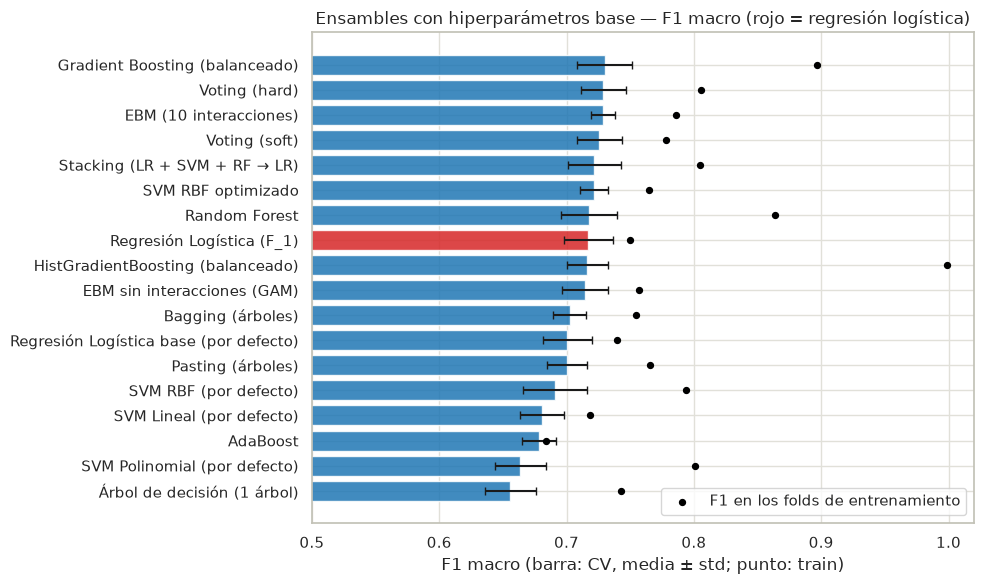

,Accuracy,Precision,Recall,F1,F1 ponderado,MCC,Kappa,ROC-AUC,Gap F1 (train−CV),Estimadores,Nº SV,Ajuste con todo Train (s)
Dummy (referencia),0.4993 ± 0.0006,0.1664 ± 0.0002,0.3333 ± 0.0000,0.2220 ± 0.0002,0.3325 ± 0.0007,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.0000,—,—,0.01
Regresión Logística base (por defecto),0.7762 ± 0.0117,0.7274 ± 0.0214,0.6909 ± 0.0171,0.7006 ± 0.0191,0.7635 ± 0.0132,0.6288 ± 0.0199,0.6230 ± 0.0193,0.8895 ± 0.0086,0.0390,—,—,0.04
SVM Lineal (por defecto),0.7725 ± 0.0097,0.7289 ± 0.0235,0.6717 ± 0.0142,0.6806 ± 0.0172,0.7519 ± 0.0115,0.6225 ± 0.0167,0.6110 ± 0.0163,0.8721 ± 0.0102,0.0380,—,—,0.06
SVM Polinomial (por defecto),0.7525 ± 0.0130,0.7154 ± 0.0220,0.6505 ± 0.0166,0.6637 ± 0.0200,0.7323 ± 0.0151,0.5897 ± 0.0235,0.5727 ± 0.0227,0.8498 ± 0.0103,0.1372,—,"2,158",0.21
SVM RBF (por defecto),0.7725 ± 0.0153,0.7306 ± 0.0239,0.6790 ± 0.0218,0.6909 ± 0.0250,0.7561 ± 0.0188,0.6225 ± 0.0269,0.6121 ± 0.0273,0.8608 ± 0.0082,0.1031,—,"2,004",0.19
Regresión Logística (F_1),0.7584 ± 0.0147,0.7203 ± 0.0201,0.7243 ± 0.0210,0.7170 ± 0.0192,0.7663 ± 0.0136,0.6178 ± 0.0227,0.6146 ± 0.0224,0.8913 ± 0.0104,0.0328,—,—,2.44
SVM RBF optimizado,0.7872 ± 0.0059,0.7496 ± 0.0142,0.7092 ± 0.0102,0.7217 ± 0.0108,0.7773 ± 0.0080,0.6483 ± 0.0105,0.6419 ± 0.0105,0.8630 ± 0.0090,0.0432,—,"1,636",0.18
Árbol de decisión (1 árbol),0.6917 ± 0.0220,0.6699 ± 0.0196,0.6657 ± 0.0200,0.6559 ± 0.0201,0.7076 ± 0.0189,0.5252 ± 0.0281,0.5175 ± 0.0299,0.8362 ± 0.0185,0.0866,—,—,0.02
Voting (hard),0.7796 ± 0.0117,0.7351 ± 0.0179,0.7255 ± 0.0180,0.7289 ± 0.0175,0.7787 ± 0.0130,0.6401 ± 0.0196,0.6389 ± 0.0195,—,0.0767,3,—,3.09
Voting (soft),0.7898 ± 0.0104,0.7491 ± 0.0176,0.7149 ± 0.0167,0.7258 ± 0.0176,0.7810 ± 0.0129,0.6525 ± 0.0178,0.6478 ± 0.0181,0.8966 ± 0.0105,0.0522,3,—,3.66


In [14]:
nombres_base = ["Dummy (referencia)", *modelos_defecto, NOMBRE_LR, "SVM RBF optimizado", "Árbol de decisión (1 árbol)", "Voting (hard)", "Voting (soft)",
                "Bagging (árboles)", "Pasting (árboles)", "Random Forest", "AdaBoost", "Gradient Boosting (balanceado)",
                "HistGradientBoosting (balanceado)", "Stacking (LR + SVM + RF → LR)", "EBM sin interacciones (GAM)", "EBM (10 interacciones)"]
display(tabla_resumen(nombres_base))
print("Recall por clase (OOF):")
display(tabla_por_clase("Recall", nombres_base).round(4))
print("F1 por clase (OOF):")
display(tabla_por_clase("F1", nombres_base).round(4))

orden = sorted(nombres_base[1:], key=lambda n: resultados_cv[n]["F1_mean"])
fig, ax = plt.subplots(figsize=(10, 6))
y_pos = np.arange(len(orden))
ax.barh(y_pos, [resultados_cv[n]["F1_mean"] for n in orden], xerr=[resultados_cv[n]["F1_std"] for n in orden], capsize=3,
        color=["tab:red" if n == NOMBRE_LR else "tab:blue" for n in orden], alpha=0.85)
ax.scatter([resultados_cv[n]["F1_train"] for n in orden], y_pos, color="black", s=18, zorder=3, label="F1 en los folds de entrenamiento")
ax.set_yticks(y_pos)
ax.set_yticklabels(orden)
ax.set_xlim(0.5, 1.02)
ax.set_xlabel("F1 macro (barra: CV, media ± std; punto: train)")
ax.set_title("Ensambles con hiperparámetros base — F1 macro (rojo = regresión logística)")
ax.legend(loc="lower right")
plt.tight_layout()
guardar_fig("03_modelos_base_f1_cv")
guardar_tabla(tabla_resumen(nombres_base), "03_modelos_base_cv")

**Interpretación.**
- **Por F1 macro (la métrica de selección)** el orden es: Gradient Boosting 0.7300, *Voting hard* 0.7289, EBM con interacciones 0.7285, *Voting soft* 0.7258, Stacking y SVM RBF 0.7217, Random Forest 0.7176, regresión logística 0.7170, HistGradientBoosting 0.7164, EBM sin interacciones 0.7143, Bagging 0.7023, Pasting 0.7004, AdaBoost 0.6784 y árbol único 0.6559. Salvo los últimos cuatro, **los modelos están en un rango de 0.016 de F1 macro, menor que una desviación entre folds (0.01–0.02)**: con 5 folds no se pueden distinguir.
- **Por Accuracy y MCC** gana el *Voting soft* (0.7898 y 0.6525), seguido del SVM RBF (0.7872 y 0.6483); **por ROC-AUC**, también el *Voting soft* (0.8966) y el *Stacking* (0.8960), por encima de la regresión logística (0.8913). Los modelos con más Accuracy son los que menos reconocen a *Enrolled* (Recall OOF 44.7% el *soft voting*, 43.6% el SVM), y los de más Recall de *Enrolled* (EBM con interacciones 64.7%, Stacking 64.6%, regresión logística 61.1%) pierden Accuracy.
- **Sobreajuste:** el gap train − CV crece con la capacidad: 0.006 (AdaBoost, que se detuvo en 10 estimadores), 0.033 (regresión logística), 0.043–0.057 (SVM y EBM), 0.146 (Random Forest), 0.167 (Gradient Boosting) y 0.282 (HistGradientBoosting). Un gap alto no implica un peor desempeño en CV, pero sí que hay margen para regularizar.

## Fase 6. Optimización de hiperparámetros

### 17. Qué se optimiza y cómo
Se optimizan los siete ensambles que tienen hiperparámetros propios (Random Forest, Bagging, Pasting, AdaBoost, Gradient Boosting, HistGradientBoosting y EBM), más los pesos del *voting* y el *blender* del *stacking*. La regresión logística y el SVM **no** se vuelven a optimizar (se conserva el acumulado). Todas las búsquedas usan los **mismos 5 folds** y la métrica de selección que se había declarado desde el Proyecto F_1: **F1 macro** (`refit = "F1"`); se registran también las otras siete.

| Modelo | Hiperparámetros explorados | Combinaciones | Búsqueda |
|---|---|---:|---|
| Random Forest | `max_features` {sqrt, log2, 0.2, 0.35, 0.5} × `min_samples_leaf` {1, 2, 3, 5, 8, 12, 20} × `max_depth` {None, 8, 12, 16} × `class_weight` {None, balanced, balanced_subsample} × `criterion` {gini, entropy} | 840 | aleatoria, 40 |
| Bagging | `max_samples` {0.3, 0.5, 0.7, 1.0} × `max_features` {0.3, 0.6, 1.0} × profundidad y `min_samples_leaf` del árbol base × `class_weight` | 480 | aleatoria, 30 |
| Pasting | igual, con `max_samples` {0.3, 0.5, 0.7, 0.9} | 480 | aleatoria, 30 |
| AdaBoost | `n_estimators` {25, 50, 100, 200, 400} × `learning_rate` {0.03, 0.1, 0.3, 1} × `max_depth` del árbol base {1, 2, 3, 4, 6, 8, 10} | 140 | exhaustiva |
| Gradient Boosting | `learning_rate` {0.02, 0.05, 0.1, 0.2} × `n_estimators` {100, 200, 300} × `max_depth` {2–5} × `subsample` {0.5, 0.7, 1} × `min_samples_leaf` {1, 5, 10, 20} × `max_features` {None, sqrt, 0.3} | 1,728 | aleatoria, 30 |
| HistGradientBoosting | `learning_rate` × `max_iter` × `max_leaf_nodes` × `min_samples_leaf` × `l2_regularization` × `max_depth` × `class_weight` | 2,592 | aleatoria, 40 |
| EBM | `interactions` {0, 10, 20} × `learning_rate` {0.01, 0.03} × `max_leaves` {2, 3} × `min_samples_leaf` {4, 20} | 24 | exhaustiva |
| Voting (hard y soft) | 5 vectores de pesos para (LR, SVM, RF, GB, HGB) | 5 | exhaustiva |
| Stacking | $C$ del *blender* ∈ {0.01, 0.1, 1, 10} con validación cruzada interna | 4 | `LogisticRegressionCV` |

Cuando la malla completa es demasiado grande, se usa **búsqueda aleatoria** (Bergstra y Bengio, 2012), que explora mejor los hiperparámetros importantes que una malla del mismo costo; con 30–40 muestras de 480–2,592 combinaciones, el resultado es una configuración buena, no *la* óptima. Cada búsqueda guarda para cada combinación las ocho métricas, la desviación entre folds y el score en entrenamiento (para medir el *gap*).

**Criterio de selección, definido antes de ver los resultados:** el ensamble final es el que tenga mayor F1 macro en CV entre los ensambles optimizados. La selección se hace con CV; Test no interviene.

In [15]:
METRICA_REFIT = Registro.METRICA_REFIT        # criterio de selección declarado de antemano: F1 macro (igual que en la práctica de SVM)
# buscar() y tabla_busqueda() están en config.py (las búsquedas se registran en `searches` / `tiempos_busqueda`)
print("Métrica de selección:", METRICA_REFIT, "| búsquedas con los mismos 5 folds")

Métrica de selección: F1 | búsquedas con los mismos 5 folds


### 17.1 Random Forest
Búsqueda aleatoria de 40 de las 840 combinaciones. Los hiperparámetros que más controlan el sobreajuste de un bosque son `min_samples_leaf` y `max_depth` (tamaño de cada árbol) y `max_features` (qué tan decorrelacionados quedan los árboles); `class_weight` decide si el bosque sacrifica Accuracy por reconocer a *Enrolled*.

In [16]:
buscar("Random Forest", crear_pipeline(RandomForestClassifier(n_estimators=300, n_jobs=1, random_state=RANDOM_STATE)),
       {"model__max_features": ["sqrt", "log2", 0.2, 0.35, 0.5],
        "model__min_samples_leaf": [1, 2, 3, 5, 8, 12, 20],
        "model__max_depth": [None, 8, 12, 16],
        "model__class_weight": [None, "balanced", "balanced_subsample"],
        "model__criterion": ["gini", "entropy"]}, n_iter=40)

print("Random Forest — 8 mejores combinaciones (F1 macro en CV):")
display(tabla_busqueda(searches["Random Forest"], n=8).round(4))

Random Forest: 40 combinaciones × 5 folds en 12 s | mejor F1 macro 0.7262 ± 0.0221 | gap 0.202
   {'model__min_samples_leaf': 2, 'model__max_features': 'log2', 'model__max_depth': 16, 'model__criterion': 'entropy', 'model__class_weight': 'balanced'}


Random Forest — 8 mejores combinaciones (F1 macro en CV):


,min_samples_leaf,max_features,max_depth,criterion,class_weight,mean_test_F1,std_test_F1,mean_train_F1,gap_F1,mean_test_Recall,mean_test_Accuracy,mean_test_MCC,mean_test_ROC-AUC,rank_test_F1
34,2,log2,16.0,entropy,balanced,0.7262,0.0221,0.9287,0.2025,0.7272,0.7691,0.6275,0.8892,1
19,5,sqrt,12.0,entropy,balanced,0.7188,0.0146,0.8296,0.1108,0.7256,0.7578,0.6161,0.8862,2
14,5,sqrt,16.0,gini,balanced_subsample,0.7188,0.0233,0.8566,0.1378,0.7177,0.7660,0.6207,0.8863,3
9,8,0.2,16.0,entropy,balanced,0.7155,0.0184,0.8175,0.1020,0.7219,0.7544,0.6118,0.8855,4
7,3,sqrt,12.0,gini,balanced,0.7145,0.0205,0.8624,0.1478,0.7192,0.7553,0.6106,0.8875,5
35,1,0.5,12.0,entropy,balanced,0.7133,0.0134,0.9741,0.2609,0.7160,0.7567,0.6108,0.8873,6
39,8,0.5,16.0,gini,balanced,0.7130,0.0162,0.8215,0.1086,0.7186,0.7533,0.6095,0.8827,7
32,3,0.35,8.0,gini,balanced_subsample,0.7119,0.0169,0.8103,0.0984,0.7163,0.7530,0.6075,0.8839,8


**Interpretación.**
- **Mejor configuración:** `min_samples_leaf = 2`, `max_features = "log2"` (6 de las 106 columnas por división), `max_depth = 16`, `criterion = "entropy"` y `class_weight = "balanced"`, con F1 macro 0.7262 ± 0.0221 en CV. Mejora +0.009 al Random Forest base (0.7176), menos de la mitad de una desviación entre folds.
- **Los ocho mejores están todos entre 0.7119 y 0.7262**: la superficie es plana y el orden entre ellos es en gran parte ruido. Lo que sí es consistente es que **ninguno usa `class_weight = None`** (6 de 8 usan `"balanced"` y 2 `"balanced_subsample"`): ponderar las clases es lo único que se ve claramente en los datos. Con `criterion` hay empate (4 *gini* y 4 *entropy*).
- **El primer lugar es también el de mayor sobreajuste:** gap 0.2025 (F1 en entrenamiento 0.9287), contra 0.11 del segundo (0.7188). El criterio declarado de antemano es el F1 macro, así que se elige el primero, pero con 40 combinaciones de ruido similar, el máximo está sobreestimado (*winner's curse*); la CV repetida de la Fase 7 lo verifica.

### 17.2 Bagging y Pasting
Mismo espacio para los dos (30 combinaciones aleatorias de 480 cada uno); lo único que cambia es si el muestreo es con o sin reemplazo. `max_samples` es el tamaño de la submuestra de cada árbol y `max_features`, la fracción de columnas que ve cada árbol (con 1.0 son *bagging* y *pasting* puros; con menos, *random subspaces*).

In [17]:
# --- Bagging y Pasting (mismo espacio; lo único que cambia es bootstrap) ---
espacio_bag = {"model__estimator__max_depth": [4, 6, 8, 12, None],
               "model__estimator__min_samples_leaf": [1, 5, 10, 20],
               "model__estimator__class_weight": [None, "balanced"],
               "model__max_features": [0.3, 0.6, 1.0]}
buscar("Bagging", crear_pipeline(BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=200, bootstrap=True, n_jobs=1, random_state=RANDOM_STATE)),
       {**espacio_bag, "model__max_samples": [0.3, 0.5, 0.7, 1.0]}, n_iter=30)
buscar("Pasting", crear_pipeline(BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=200, bootstrap=False, n_jobs=1, random_state=RANDOM_STATE)),
       {**espacio_bag, "model__max_samples": [0.3, 0.5, 0.7, 0.9]}, n_iter=30)

print("Bagging — 8 mejores combinaciones (F1 macro en CV):")
display(tabla_busqueda(searches["Bagging"], n=8).round(4))

print("Pasting — 8 mejores combinaciones (F1 macro en CV):")
display(tabla_busqueda(searches["Pasting"], n=8).round(4))

Bagging: 30 combinaciones × 5 folds en 11 s | mejor F1 macro 0.7101 ± 0.0195 | gap 0.171
   {'model__max_samples': 1.0, 'model__max_features': 0.3, 'model__estimator__min_samples_leaf': 5, 'model__estimator__max_depth': 12, 'model__estimator__class_weight': 'balanced'}


Pasting: 30 combinaciones × 5 folds en 12 s | mejor F1 macro 0.7189 ± 0.0200 | gap 0.193
   {'model__max_samples': 0.9, 'model__max_features': 0.3, 'model__estimator__min_samples_leaf': 5, 'model__estimator__max_depth': 12, 'model__estimator__class_weight': 'balanced'}


Bagging — 8 mejores combinaciones (F1 macro en CV):


,max_samples,max_features,estimator__min_samples_leaf,estimator__max_depth,estimator__class_weight,mean_test_F1,std_test_F1,mean_train_F1,gap_F1,mean_test_Recall,mean_test_Accuracy,mean_test_MCC,mean_test_ROC-AUC,rank_test_F1
4,1.0,0.3,5,12.0,balanced,0.7101,0.0195,0.8808,0.1707,0.7070,0.7604,0.6099,0.8807,1
1,0.7,0.6,10,12.0,balanced,0.7099,0.0123,0.7948,0.0848,0.7132,0.7530,0.6058,0.8805,2
26,0.7,1.0,5,8.0,balanced,0.7094,0.0181,0.7954,0.0860,0.7131,0.7522,0.6054,0.8801,3
13,0.7,1.0,1,6.0,balanced,0.7078,0.0161,0.7695,0.0616,0.7135,0.7482,0.6020,0.8771,4
2,0.7,1.0,1,12.0,balanced,0.7038,0.0125,0.9405,0.2367,0.6987,0.7601,0.6074,0.8824,5
21,0.5,1.0,10,None,balanced,0.7036,0.0152,0.7645,0.0609,0.7054,0.7494,0.5986,0.8763,6
19,1.0,1.0,1,None,None,0.7012,0.0122,1.0000,0.2988,0.6917,0.7717,0.6222,0.8795,7
28,0.5,0.3,5,6.0,balanced,0.7002,0.0168,0.7487,0.0485,0.7059,0.7412,0.5890,0.8739,8


Pasting — 8 mejores combinaciones (F1 macro en CV):


,max_samples,max_features,estimator__min_samples_leaf,estimator__max_depth,estimator__class_weight,mean_test_F1,std_test_F1,mean_train_F1,gap_F1,mean_test_Recall,mean_test_Accuracy,mean_test_MCC,mean_test_ROC-AUC,rank_test_F1
4,0.9,0.3,5,12.0,balanced,0.7189,0.0200,0.9117,0.1928,0.7187,0.7640,0.6185,0.8824,1
1,0.7,0.6,10,12.0,balanced,0.7140,0.0181,0.8267,0.1126,0.7174,0.7567,0.6115,0.8836,2
28,0.5,0.3,5,6.0,balanced,0.7049,0.0182,0.7529,0.0480,0.7122,0.7434,0.5943,0.8762,3
26,0.7,1.0,5,8.0,balanced,0.7045,0.0089,0.8103,0.1058,0.7113,0.7434,0.5959,0.8795,4
7,0.9,0.3,20,8.0,balanced,0.7045,0.0195,0.7617,0.0572,0.7137,0.7417,0.5938,0.8754,5
17,0.9,0.3,20,12.0,balanced,0.7043,0.0219,0.7787,0.0744,0.7122,0.7431,0.5944,0.8757,6
25,0.7,0.6,20,None,balanced,0.7035,0.0186,0.7628,0.0593,0.7106,0.7429,0.5953,0.8791,7
13,0.7,1.0,1,6.0,balanced,0.7013,0.0166,0.7704,0.0691,0.7127,0.7347,0.5892,0.8761,8


**Interpretación.**
- **Bagging:** `max_samples = 1.0`, `max_features = 0.3`, árbol base con `min_samples_leaf = 5`, `max_depth = 12` y `class_weight = "balanced"`: F1 macro 0.7101 ± 0.0195 (base: 0.7023). **Pasting:** `max_samples = 0.9`, mismos hiperparámetros del árbol: 0.7189 ± 0.0200 (base: 0.7004).
- **Los dos eligen `max_features = 0.3`** (cada árbol ve solo ≈32 de las 106 columnas, la técnica de *random subspaces*): decorrelaciona los árboles, igual que `max_features` en un Random Forest. Y casi todos los mejores usan `class_weight = "balanced"` en el árbol base (7 de 8 en *bagging*, 8 de 8 en *pasting*).
- **El *pasting* queda 0.009 por encima del *bagging*** en la búsqueda, pero con desviaciones de ≈0.02 no es una diferencia que se pueda sostener; ambos se quedan por debajo del Random Forest optimizado (0.7262).
- **Hay configuraciones casi iguales con la mitad de sobreajuste**: en *bagging*, el segundo lugar (`max_samples = 0.7`, `max_features = 0.6`, `min_samples_leaf = 10`) tiene F1 macro 0.7099 con un gap de 0.085, contra 0.171 del primero. El mejor F1 y el mejor compromiso no son la misma configuración.

### 17.3 Boosting
- **AdaBoost:** búsqueda exhaustiva de 140 combinaciones (el espacio se amplió después de ver que, con una malla menor, la mejor profundidad quedaba en el borde).
- **Gradient Boosting:** 30 de 1,728 combinaciones. `learning_rate` y `n_estimators` trabajan juntos (pasos pequeños requieren más árboles); `max_depth`, `min_samples_leaf`, `subsample` y `max_features` regularizan cada árbol.
- **HistGradientBoosting:** 40 de 2,592 combinaciones, con `l2_regularization` y `max_leaf_nodes` como controles adicionales.

In [18]:
# --- AdaBoost ---
buscar("AdaBoost", crear_pipeline(AdaBoostClassifier(
        estimator=DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE), random_state=RANDOM_STATE)),
       {"model__n_estimators": [25, 50, 100, 200, 400], "model__learning_rate": [0.03, 0.1, 0.3, 1.0],
        "model__estimator__max_depth": [1, 2, 3, 4, 6, 8, 10]})

print("AdaBoost — 8 mejores combinaciones (F1 macro en CV):")
display(tabla_busqueda(searches["AdaBoost"], n=8).round(4))

AdaBoost: 140 combinaciones × 5 folds en 35 s | mejor F1 macro 0.7177 ± 0.0187 | gap 0.087
   {'model__estimator__max_depth': 6, 'model__learning_rate': 0.1, 'model__n_estimators': 50}


AdaBoost — 8 mejores combinaciones (F1 macro en CV):


,estimator__max_depth,learning_rate,n_estimators,mean_test_F1,std_test_F1,mean_train_F1,gap_F1,mean_test_Recall,mean_test_Accuracy,mean_test_MCC,mean_test_ROC-AUC,rank_test_F1
86,6,0.1,50,0.7177,0.0187,0.8043,0.0867,0.7243,0.7556,0.6143,0.8830,1
104,8,0.03,400,0.7165,0.0197,0.9482,0.2317,0.7154,0.7641,0.6189,0.8751,2
107,8,0.1,100,0.7157,0.0120,0.9430,0.2273,0.7157,0.7621,0.6162,0.8762,3
88,6,0.1,200,0.7152,0.0161,0.8067,0.0915,0.7220,0.7533,0.6114,0.8829,4
89,6,0.1,400,0.7152,0.0161,0.8067,0.0915,0.7220,0.7533,0.6114,0.8829,4
87,6,0.1,100,0.7152,0.0161,0.8067,0.0915,0.7220,0.7533,0.6114,0.8829,4
123,10,0.03,200,0.7144,0.0183,0.9959,0.2814,0.7103,0.7660,0.6185,0.8743,7
108,8,0.1,200,0.7142,0.0106,0.9497,0.2355,0.7130,0.7621,0.6150,0.8754,8


In [19]:
# --- Gradient Boosting (balanceado) ---
buscar("Gradient Boosting", crear_pipeline(GradientBoostingBalanceado(random_state=RANDOM_STATE)),
       {"model__learning_rate": [0.02, 0.05, 0.1, 0.2], "model__n_estimators": [100, 200, 300],
        "model__max_depth": [2, 3, 4, 5], "model__subsample": [0.5, 0.7, 1.0],
        "model__min_samples_leaf": [1, 5, 10, 20], "model__max_features": [None, "sqrt", 0.3]}, n_iter=30)

print("Gradient Boosting — 8 mejores combinaciones (F1 macro en CV):")
display(tabla_busqueda(searches["Gradient Boosting"], n=8).round(4))

Gradient Boosting: 30 combinaciones × 5 folds en 17 s | mejor F1 macro 0.7316 ± 0.0191 | gap 0.185
   {'model__subsample': 0.7, 'model__n_estimators': 300, 'model__min_samples_leaf': 5, 'model__max_features': 0.3, 'model__max_depth': 4, 'model__learning_rate': 0.05}


Gradient Boosting — 8 mejores combinaciones (F1 macro en CV):


,subsample,n_estimators,min_samples_leaf,max_features,max_depth,learning_rate,mean_test_F1,std_test_F1,mean_train_F1,gap_F1,mean_test_Recall,mean_test_Accuracy,mean_test_MCC,mean_test_ROC-AUC,rank_test_F1
23,0.7,300,5,0.3,4,0.05,0.7316,0.0191,0.9168,0.1852,0.7344,0.7734,0.6358,0.8944,1
29,1.0,300,10,sqrt,3,0.05,0.7290,0.0241,0.8149,0.0859,0.7376,0.7655,0.6299,0.8922,2
7,0.7,300,5,0.3,5,0.05,0.7282,0.0213,0.9764,0.2482,0.7270,0.7754,0.6355,0.8939,3
0,1.0,200,10,sqrt,3,0.05,0.7278,0.0251,0.7857,0.0579,0.7370,0.7635,0.6273,0.8898,4
11,1.0,100,10,0.3,4,0.1,0.7278,0.0194,0.8604,0.1327,0.7339,0.7677,0.6306,0.8950,5
2,0.7,300,5,0.3,3,0.05,0.7274,0.0189,0.8428,0.1155,0.7338,0.7672,0.6300,0.8945,6
10,1.0,200,1,0.3,3,0.2,0.7267,0.0211,0.9393,0.2126,0.7297,0.7703,0.6306,0.8899,7
20,1.0,300,1,None,3,0.05,0.7261,0.0185,0.8504,0.1243,0.7340,0.7646,0.6271,0.8951,8


In [20]:
# --- HistGradientBoosting ---
buscar("HistGradientBoosting", crear_pipeline(HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE)),
       {"model__learning_rate": [0.02, 0.05, 0.1, 0.2], "model__max_iter": [100, 200, 400],
        "model__max_leaf_nodes": [7, 15, 31], "model__min_samples_leaf": [10, 20, 40, 80],
        "model__l2_regularization": [0, 1, 10], "model__max_depth": [None, 3, 5],
        "model__class_weight": [None, "balanced"]}, n_iter=40)

print("HistGradientBoosting — 8 mejores combinaciones (F1 macro en CV):")
display(tabla_busqueda(searches["HistGradientBoosting"], n=8).round(4))

HistGradientBoosting: 40 combinaciones × 5 folds en 14 s | mejor F1 macro 0.7340 ± 0.0189 | gap 0.213
   {'model__min_samples_leaf': 10, 'model__max_leaf_nodes': 15, 'model__max_iter': 100, 'model__max_depth': None, 'model__learning_rate': 0.1, 'model__l2_regularization': 1, 'model__class_weight': 'balanced'}


HistGradientBoosting — 8 mejores combinaciones (F1 macro en CV):


,min_samples_leaf,max_leaf_nodes,max_iter,max_depth,learning_rate,l2_regularization,class_weight,mean_test_F1,std_test_F1,mean_train_F1,gap_F1,mean_test_Recall,mean_test_Accuracy,mean_test_MCC,mean_test_ROC-AUC,rank_test_F1
26,10,15,100,None,0.1,1,balanced,0.7340,0.0189,0.9473,0.2133,0.7348,0.7785,0.6421,0.8970,1
33,40,7,100,3.0,0.1,0,balanced,0.7315,0.0152,0.8222,0.0907,0.7399,0.7683,0.6338,0.8958,2
14,20,7,200,None,0.1,1,balanced,0.7312,0.0173,0.9160,0.1848,0.7344,0.7745,0.6372,0.8951,3
17,10,31,200,5.0,0.05,1,balanced,0.7309,0.0150,0.9434,0.2125,0.7331,0.7745,0.6370,0.8960,4
25,20,15,400,None,0.02,0,balanced,0.7288,0.0196,0.9323,0.2035,0.7305,0.7737,0.6352,0.8950,5
1,20,7,100,3.0,0.2,1,balanced,0.7255,0.0176,0.8842,0.1587,0.7319,0.7655,0.6267,0.8944,6
19,20,31,100,3.0,0.2,1,balanced,0.7251,0.0107,0.8913,0.1662,0.7295,0.7677,0.6280,0.8926,7
21,40,7,100,None,0.05,0,balanced,0.7245,0.0186,0.7942,0.0697,0.7336,0.7615,0.6239,0.8944,8


**Interpretación.**
- **AdaBoost:** `max_depth = 6`, `learning_rate = 0.1` y `n_estimators = 50`, con F1 macro 0.7177 ± 0.0187 (base: 0.6784, +0.039): es la mejora más grande de una optimización, y sale de abandonar los árboles de profundidad 2. La profundidad ganadora es interior en la malla ampliada (se exploró hasta 10). **Es también la configuración más regularizada de las mejores:** gap 0.087, contra 0.23–0.28 de las que usan árboles de profundidad 8 a 10 con el mismo F1 aproximado (0.714 a 0.717). Los tres resultados idénticos (0.7152, con `max_depth = 6`, `learning_rate = 0.1` y `n_estimators` 100, 200 y 400) confirman que el algoritmo se detiene solo antes de llegar a esos números de estimadores.
- **Gradient Boosting:** `learning_rate = 0.05`, 300 árboles de profundidad 4, `subsample = 0.7`, `max_features = 0.3` y `min_samples_leaf = 5`: F1 macro 0.7316 ± 0.0191, apenas +0.0016 sobre el modelo base (0.7300) y con más gap (0.185 contra 0.167). Los ocho mejores están entre 0.7261 y 0.7316, y seis usan `learning_rate = 0.05`, con árboles pequeños (profundidad 3 a 5). **Gradient Boosting ya venía bien configurado y la búsqueda no encontró nada claramente mejor.** Hay configuraciones casi iguales con mucho menos sobreajuste: el cuarto lugar (200 árboles, profundidad 3, `max_features = "sqrt"`) tiene 0.7278 con gap 0.058.
- **HistGradientBoosting:** `max_leaf_nodes = 15`, `min_samples_leaf = 10`, `max_iter = 100`, `learning_rate = 0.1`, `l2_regularization = 1`, sin límite de profundidad y `class_weight = "balanced"`: F1 macro 0.7340 ± 0.0189 (base: 0.7164, +0.018) y gap de 0.213 (base: 0.282). Las siete primeras combinaciones usan `class_weight = "balanced"`. Aquí **sí hay una mejora**, que viene de entrenar la mitad de iteraciones (100 contra 200) y regularizar con L2. Tres de sus hiperparámetros (`max_iter`, `min_samples_leaf` y `max_depth`) quedaron en el borde de su rango; se revisa en la Sección 19.

### 17.4 Explainable Boosting Machine
Búsqueda exhaustiva de 24 combinaciones: número de interacciones (0 es el GAM puro), `learning_rate`, `max_leaves` (profundidad de cada árbol de un solo paso) y `min_samples_leaf`. Es la búsqueda más lenta por costo por ajuste, no por número de combinaciones.

In [21]:
# --- EBM (GAM con boosting) ---
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    buscar("EBM", crear_ebm(0),
           {"model__interactions": [0, 10, 20], "model__learning_rate": [0.01, 0.03],
            "model__max_leaves": [2, 3], "model__min_samples_leaf": [4, 20]})

print("EBM — 10 mejores combinaciones (F1 macro en CV):")
display(tabla_busqueda(searches["EBM"], n=10).round(4))

EBM: 24 combinaciones × 5 folds en 41 s | mejor F1 macro 0.7309 ± 0.0139 | gap 0.064
   {'model__interactions': 10, 'model__learning_rate': 0.03, 'model__max_leaves': 3, 'model__min_samples_leaf': 4}


EBM — 10 mejores combinaciones (F1 macro en CV):


,interactions,learning_rate,max_leaves,min_samples_leaf,mean_test_F1,std_test_F1,mean_train_F1,gap_F1,mean_test_Recall,mean_test_Accuracy,mean_test_MCC,mean_test_ROC-AUC,rank_test_F1
14,10,0.03,3,4,0.7309,0.0139,0.7949,0.0640,0.7398,0.7683,0.6343,0.8936,1
18,20,0.01,3,4,0.7297,0.0130,0.7986,0.0689,0.7380,0.7683,0.6337,0.8940,2
15,10,0.03,3,20,0.7297,0.0112,0.7949,0.0653,0.7391,0.7669,0.6326,0.8928,3
19,20,0.01,3,20,0.7293,0.0172,0.7996,0.0703,0.7381,0.7672,0.6324,0.8939,4
10,10,0.01,3,4,0.7278,0.0131,0.7923,0.0645,0.7366,0.7655,0.6300,0.8951,5
11,10,0.01,3,20,0.7273,0.0159,0.7897,0.0625,0.7359,0.7655,0.6294,0.8950,6
13,10,0.03,2,20,0.7267,0.0091,0.7855,0.0588,0.7368,0.7635,0.6282,0.8920,7
12,10,0.03,2,4,0.7252,0.0074,0.7883,0.0631,0.7346,0.7626,0.6263,0.8929,8
23,20,0.03,3,20,0.7249,0.0150,0.8030,0.0780,0.7335,0.7635,0.6265,0.8940,9
8,10,0.01,2,4,0.7248,0.0102,0.7857,0.0610,0.7332,0.7632,0.6262,0.8928,10


**Interpretación.**

- **Mejor configuración:** `interactions = 10`, `learning_rate = 0.03`, `max_leaves = 3` y `min_samples_leaf = 4`, con F1 macro 0.7309 ± 0.0139. Frente al EBM base con 10 interacciones (0.7285) la mejora es de +0.0024, es decir, **prácticamente nula**. Frente al GAM sin interacciones (0.7143) sí hay +0.017, pero esa diferencia viene de *tener* interacciones, no de ajustar los demás hiperparámetros.
- **Las diez mejores combinaciones están en un intervalo de 0.0061** (0.7248 a 0.7309), menos de la mitad de la desviación estándar entre folds (≈ 0.014). Elegir entre ellas es elegir entre empates. Todas tienen interacciones (10 o 20), así que `interactions = 0` queda por debajo de 0.7248; entre 10 y 20 no hay diferencia apreciable (0.7309 contra 0.7297), y lo mismo pasa con `min_samples_leaf` 4 contra 20 (0.7309 contra 0.7297).
- **Es el modelo con menos sobreajuste de la tabla:** gap train − CV de 0.064, contra 0.17–0.21 de Random Forest, Bagging, Pasting, Gradient Boosting e HistGradientBoosting y 0.087 de AdaBoost. Es el costo de ser un modelo aditivo: no puede memorizar combinaciones raras de variables, solo las interacciones que se le permiten.
- **Es también el de mayor *recall* macro** entre los optimizados (0.7398, apenas por encima de *Voting hard* y Stacking, 0.7395 y 0.7387), lo que va con su mejor desempeño en la clase *Enrolled* (ver la Sección 22).
- **Es la búsqueda con mayor costo por ajuste:** 24 combinaciones × 5 folds tomaron 43 s, contra 11 a 18 s de las demás búsquedas (salvo AdaBoost, 35 s, que explora 140 combinaciones). Un EBM tarda ≈ 3 s en ajustarse, de 2 a 6 veces más que Random Forest, Bagging, Pasting, AdaBoost, Gradient Boosting o HistGradientBoosting (0.5 a 1.6 s).

### 18. Mapas de calor y curvas de los hiperparámetros
**Random Forest: tamaño de las hojas contra número de variables por división.** Se fijan los demás hiperparámetros en los de la mejor configuración y se barre una malla de 6 × 6 de `min_samples_leaf` × `max_features`, mostrando el F1 macro en CV, el F1 en entrenamiento y su diferencia (el *gap*). Después se mide el efecto del **número de árboles**: un bosque no sobreajusta por tener más árboles; su error se estabiliza y más árboles solo cuestan tiempo.

Random Forest (mapa de calor): 36 combinaciones × 5 folds en 15 s | mejor F1 macro 0.7247 ± 0.0203 | gap 0.274
   {'model__max_features': 0.2, 'model__min_samples_leaf': 1}


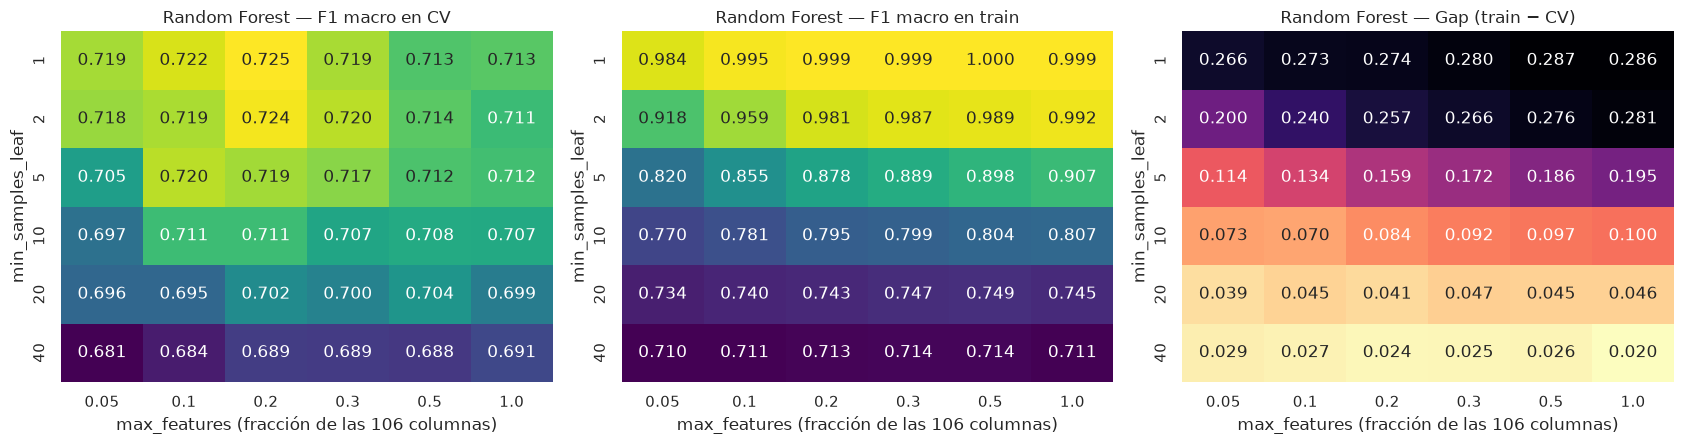

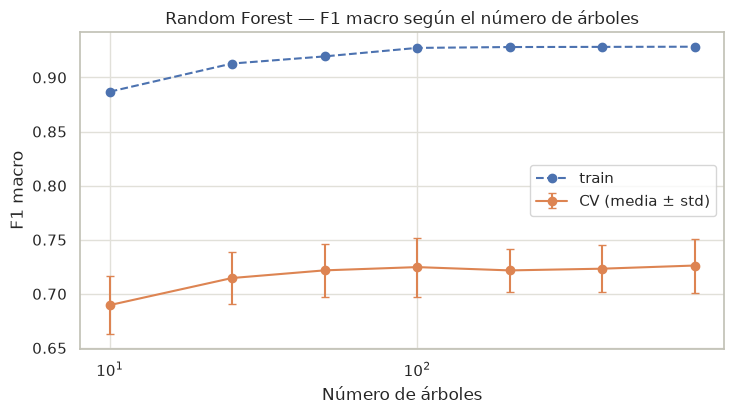

,F1 train,F1 CV,std CV
n_estimators,,,
10,0.8868,0.6896,0.0269
25,0.9129,0.7146,0.0240
50,0.9195,0.7217,0.0242
100,0.9273,0.7247,0.0273
200,0.9281,0.7217,0.0198
400,0.9283,0.7233,0.0218
800,0.9284,0.7262,0.0249


In [22]:
# Mapa de calor del Random Forest: min_samples_leaf × max_features (el resto de hiperparámetros, en su mejor valor)
rf_mejor = searches["Random Forest"].best_estimator_
espacio_rf = {"model__min_samples_leaf": [1, 2, 5, 10, 20, 40],
              "model__max_features": [0.05, 0.1, 0.2, 0.3, 0.5, 1.0]}
buscar("Random Forest (mapa de calor)", clone(rf_mejor), espacio_rf)

res_rf = pd.DataFrame(searches["Random Forest (mapa de calor)"].cv_results_)
res_rf["min_samples_leaf"] = res_rf["param_model__min_samples_leaf"].astype(int)
res_rf["max_features"] = res_rf["param_model__max_features"].astype(float)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (col, titulo, cmap) in zip(axes, [("mean_test_F1", "F1 macro en CV", "viridis"),
                                           ("mean_train_F1", "F1 macro en train", "viridis"),
                                           ("gap", "Gap (train − CV)", "magma_r")]):
    res_rf["gap"] = res_rf["mean_train_F1"] - res_rf["mean_test_F1"]
    sns.heatmap(res_rf.pivot(index="min_samples_leaf", columns="max_features", values=col), annot=True, fmt=".3f",
                cmap=cmap, ax=ax, cbar=False)
    ax.set_title(f"Random Forest — {titulo}")
    ax.set_xlabel("max_features (fracción de las 106 columnas)")
    ax.set_ylabel("min_samples_leaf")
plt.tight_layout()
guardar_fig("03_rf_mapa_calor")

# Número de árboles: el error de un bosque se estabiliza; más árboles no sobreajustan, solo cuestan tiempo
n_arboles = N_ARBOLES
tr, va = validation_curve(clone(rf_mejor), X_train, y_train, param_name="model__n_estimators", param_range=n_arboles,
                          cv=cv, scoring="f1_macro", n_jobs=N_JOBS)
curva_arboles = pd.DataFrame({"F1 train": tr.mean(axis=1), "F1 CV": va.mean(axis=1), "std CV": va.std(axis=1)},
                             index=pd.Index(n_arboles, name="n_estimators"))
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(n_arboles, curva_arboles["F1 train"], "o--", label="train")
ax.errorbar(n_arboles, curva_arboles["F1 CV"], yerr=curva_arboles["std CV"], fmt="o-", capsize=3, label="CV (media ± std)")
ax.set_xscale("log")
ax.set_xlabel("Número de árboles")
ax.set_ylabel("F1 macro")
ax.set_title("Random Forest — F1 macro según el número de árboles")
ax.legend()
plt.tight_layout()
guardar_fig("03_rf_numero_de_arboles")
curva_arboles.round(4)

**Interpretación.**

- **`min_samples_leaf` es el hiperparámetro que domina el mapa; `max_features` casi no importa.** En cada columna, el F1 de CV baja de ≈ 0.72 con hojas de 1 a 2 observaciones a ≈ 0.69 con hojas de 40. En cada fila, en cambio, moverse entre `max_features` 0.05 y 1.0 cambia el F1 en menos de 0.02, con un máximo suave en 0.1 a 0.3 (el mejor es 0.2 con hojas de 1: 0.725, gap 0.274).
- **El mejor F1 y el menor sobreajuste están en esquinas opuestas.** Con hojas de 1 el F1 de entrenamiento es ≈ 1.00 (gap 0.27 a 0.29); con hojas de 40 el gap es de 0.02 a 0.03, pero el F1 de CV cae unos 0.035. Entre `min_samples_leaf` 1 y 5 la diferencia de F1 (0.725 contra 0.719 con `max_features = 0.2`) es menor que una desviación estándar (≈ 0.02), mientras que el gap baja de 0.274 a 0.159. **Estadísticamente son empates; en términos de sobreajuste, no.** La búsqueda de la Sección 17.1 eligió hojas de 2 por el criterio fijado de antemano (F1 de CV), pero habría sido igual de defendible quedarse con 5.
- **Más árboles no sobreajustan, pero tampoco ayudan.** El F1 de CV sube de 0.690 con 10 árboles a 0.715 con 25 y 0.722 con 50, y desde 100 árboles se queda en 0.722 a 0.726 sin tendencia (la desviación estándar entre folds es de 0.02 a 0.027). El F1 de entrenamiento también se estabiliza (0.927 a 0.928). Pasar de 100 a 800 árboles multiplica el costo por 8 sin ganancia medible; con 100 a 200 es suficiente.

**Boosting: el compromiso entre `learning_rate` y número de árboles.** En *boosting*, sí se sobreajusta al añadir árboles. Se entrena cada modelo con la configuración óptima pero con muchos árboles y se mide el F1 macro tras cada árbol añadido (con `staged_predict`) en los 5 folds, para varios `learning_rate`: la curva de validación sube, alcanza un máximo y luego baja o se aplana, mientras la de entrenamiento sigue creciendo.

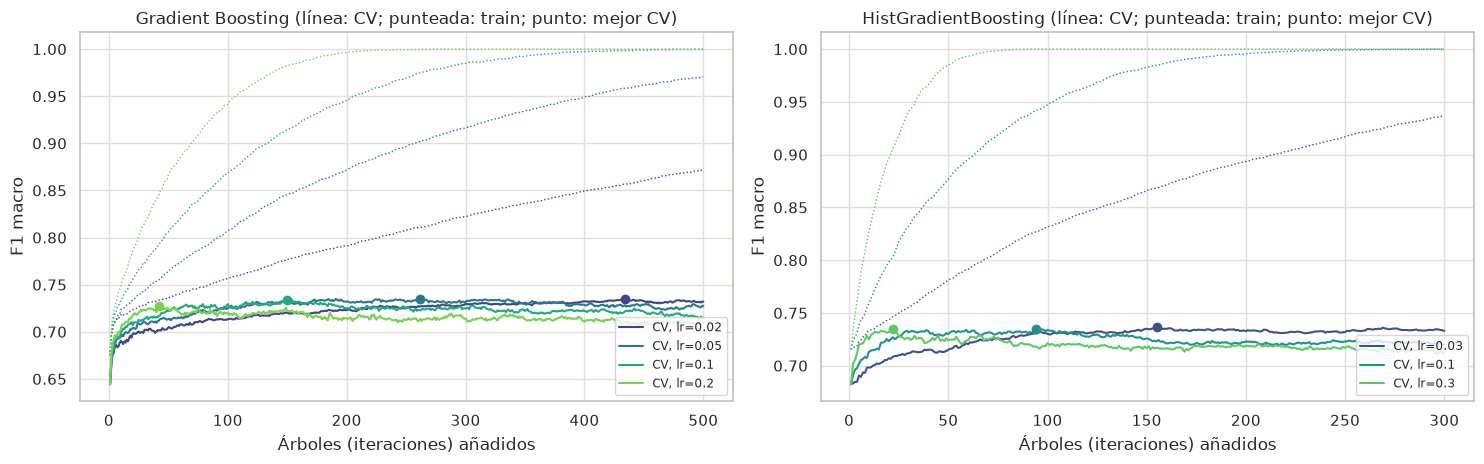

Mejor nº de árboles  F1 CV en el mejor  \
Modelo               learning_rate                                           
Gradient Boosting    0.02                           434             0.7344   
                     0.05                           262             0.7351   
                     0.10                           150             0.7340   
                     0.20                            42             0.7273   
HistGradientBoosting 0.03                           155             0.7366   
                     0.10                            94             0.7352   
                     0.30                            22             0.7352   

                                    F1 CV al final  Gap al final (train−CV)  
Modelo               learning_rate                                           
Gradient Boosting    0.02                   0.7319                   0.1396  
                     0.05                   0.7275                   0.2431  
                     0.10                   0.7147                   0.2851  
                     0.20                   0.7095                   0.2905  
HistGradientBoosting 0.03                   0.7331                   0.2038  
                     0.10                   0.7199                   0.2800  
                     0.30                   0.7130                   0.2870

In [23]:
# Boosting: F1 macro tras cada árbol añadido, para varios learning rates (CV de 5 folds, una sola corrida por learning rate)
import warnings; warnings.filterwarnings("ignore", message="A worker stopped")
from joblib import Parallel, delayed

def una_corrida(clave, param_n, lr, n_max, tr, va):
    pipe = clone(searches[clave].best_estimator_).set_params(model__learning_rate=lr, **{f"model__{param_n}": n_max})
    pipe.fit(X_train.iloc[tr], y_train[tr])
    prep, modelo = pipe.named_steps["preprocessor"], pipe.named_steps["model"]
    f_tr = [f1_score(y_train[tr], p, average="macro") for p in modelo.staged_predict(prep.transform(X_train.iloc[tr]))]
    f_va = [f1_score(y_train[va], p, average="macro") for p in modelo.staged_predict(prep.transform(X_train.iloc[va]))]
    return f_tr, f_va

def curva_etapas(clave, param_n, lrs, n_max):
    folds = list(cv.split(X_train, y_train))
    salida = Parallel(n_jobs=N_JOBS)(delayed(una_corrida)(clave, param_n, lr, n_max, tr, va)
                                     for lr in lrs for tr, va in folds)
    out = {}
    for i, lr in enumerate(lrs):
        parte = salida[i * len(folds):(i + 1) * len(folds)]
        out[lr] = (np.mean([p[0] for p in parte], axis=0), np.mean([p[1] for p in parte], axis=0),
                   np.std([p[1] for p in parte], axis=0))
    return out

curvas_boost = {"Gradient Boosting": curva_etapas("Gradient Boosting", "n_estimators", [0.02, 0.05, 0.1, 0.2], N_MAX_GB),
                "HistGradientBoosting": curva_etapas("HistGradientBoosting", "max_iter", [0.03, 0.1, 0.3], N_MAX_HGB)}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, (nombre, curvas) in zip(axes, curvas_boost.items()):
    for (lr, (f_tr, f_va, s_va)), color in zip(curvas.items(), sns.color_palette("viridis", len(curvas))):
        x = np.arange(1, len(f_va) + 1)
        ax.plot(x, f_va, color=color, label=f"CV, lr={lr}")
        ax.plot(x, f_tr, color=color, ls=":", lw=1)
        ax.plot(x[f_va.argmax()], f_va.max(), "o", color=color)
    ax.set_xlabel("Árboles (iteraciones) añadidos")
    ax.set_ylabel("F1 macro")
    ax.set_title(f"{nombre} (línea: CV; punteada: train; punto: mejor CV)")
    ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
guardar_fig("03_boosting_curvas_por_etapa")

filas = []
for nombre, curvas in curvas_boost.items():
    for lr, (f_tr, f_va, s_va) in curvas.items():
        filas.append({"Modelo": nombre, "learning_rate": lr, "Mejor nº de árboles": int(f_va.argmax()) + 1,
                      "F1 CV en el mejor": f_va.max(), "F1 CV al final": f_va[-1], "Gap al final (train−CV)": f_tr[-1] - f_va[-1]})
pd.DataFrame(filas).set_index(["Modelo", "learning_rate"]).round(4)

**Interpretación.**

- **El techo es el mismo para cualquier `learning_rate`.** El mejor F1 de CV de cada curva está entre 0.727 y 0.735 en Gradient Boosting y entre 0.735 y 0.737 en HistGradientBoosting. Esas diferencias (< 0.01) son menores que la desviación estándar entre folds (≈ 0.019). Lo que cambia con la tasa de aprendizaje es *cuántos árboles* hacen falta: 434 con 0.02, 262 con 0.05, 150 con 0.1 y 42 con 0.2 en Gradient Boosting; 155, 94 y 22 con 0.03, 0.1 y 0.3 en HistGradientBoosting. Las tasas pequeñas llegan al mismo lugar con un camino más largo.
- **Pasarse de árboles cuesta, y cuesta más con tasas grandes.** Al final de la curva el F1 de CV es menor que en el mejor punto: −0.0025 con `learning_rate = 0.02`, pero −0.018 con 0.2 en Gradient Boosting y −0.022 con 0.3 en HistGradientBoosting. Mientras tanto el F1 de entrenamiento llega a ≈ 1.00 y el gap final de Gradient Boosting es de 0.14 con la tasa más baja y de 0.29 con la más alta. **Una tasa pequeña perdona más un `n_estimators` mal elegido.**
- **Estas curvas muestran el máximo de una curva ruidosa, así que son optimistas.** Los máximos de las curvas (hasta 0.7366) están un poco por encima de lo que encontró la búsqueda de la Sección 17.3 (0.7316 y 0.7340), porque aquí se elige el mejor punto entre 300 a 500 posibles *sobre los mismos folds* con los que se mide. Sirven para entender la forma de la curva, no para reportar un F1.

### 19. ¿Los óptimos caen en el borde de su rango?
Si el mejor valor de un hiperparámetro numérico es el mínimo o el máximo de lo explorado, el óptimo real podría estar fuera de la malla. La tabla lo revisa automáticamente para todas las búsquedas.

In [24]:
# ¿El mejor valor de cada hiperparámetro numérico cae en el borde de su rango? Si sí, el óptimo podría estar fuera de lo explorado.
def es_num(v):
    return isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool)

filas = []
for nombre, s in searches.items():
    if nombre.startswith("Voting") or "mapa de calor" in nombre:
        continue
    espacio = s.param_grid if hasattr(s, "param_grid") else s.param_distributions
    for p, rango in espacio.items():
        mejor = s.best_params_[p]
        nums = [v for v in rango if es_num(v)]
        if mejor is None:
            borde = "sí (sin límite)"
        elif es_num(mejor) and len(nums) >= 3:
            borde = "sí" if mejor in (min(nums), max(nums)) else "no"
        else:
            borde = "—"                                   # categórico o con solo 2 valores
        filas.append({"Modelo": nombre, "Hiperparámetro": p.replace("model__", ""),
                      "Rango explorado": ", ".join("None" if v is None else str(v) for v in rango),
                      "Mejor": "None" if mejor is None else mejor, "¿En el borde?": borde})
tabla_borde = pd.DataFrame(filas)
display(tabla_borde.style.hide(axis="index"))
print("Hiperparámetros numéricos en el borde, por modelo:")
display(tabla_borde[tabla_borde["¿En el borde?"].str.startswith("sí")].groupby("Modelo")["Hiperparámetro"].apply(", ".join).to_frame())

Modelo,Hiperparámetro,Rango explorado,Mejor,¿En el borde?
Random Forest,max_features,"sqrt, log2, 0.2, 0.35, 0.5",log2,—
Random Forest,min_samples_leaf,"1, 2, 3, 5, 8, 12, 20",2,no
Random Forest,max_depth,"None, 8, 12, 16",16,sí
Random Forest,class_weight,"None, balanced, balanced_subsample",balanced,—
Random Forest,criterion,"gini, entropy",entropy,—
Bagging,estimator__max_depth,"4, 6, 8, 12, None",12,sí
Bagging,estimator__min_samples_leaf,"1, 5, 10, 20",5,no
Bagging,estimator__class_weight,"None, balanced",balanced,—
Bagging,max_features,"0.3, 0.6, 1.0",0.300000,sí
Bagging,max_samples,"0.3, 0.5, 0.7, 1.0",1.000000,sí


Hiperparámetros numéricos en el borde, por modelo:


,Hiperparámetro
Modelo,
Bagging,"estimator__max_depth, max_features, max_samples"
Gradient Boosting,n_estimators
HistGradientBoosting,"max_iter, min_samples_leaf, max_depth"
Pasting,"estimator__max_depth, max_features, max_samples"
Random Forest,max_depth


**Interpretación.**

La tabla marca como "borde" a todo valor numérico igual al mínimo o al máximo explorado. Hay que leerla con cuidado, porque no todas las marcas son lo mismo:

- **Falsos bordes.** `max_depth = 16` en Random Forest y `max_depth = 12` en Bagging y Pasting son el mayor valor *finito* de su rango, pero ese rango incluye también `None` (sin límite), que se probó y no ganó: la profundidad no está truncada por la malla. En HistGradientBoosting gana `max_depth = None`, es decir, no hace falta limitar la profundidad porque `max_leaf_nodes = 15` ya acota el árbol (y ese sí es un valor interior).
- **Bordes que pueden importar.** `max_features = 0.3` en Bagging y Pasting es el valor más bajo explorado. Es consistente con el mapa de calor del Random Forest (Sección 18), donde 0.1 a 0.3 funcionaba mejor que 0.5 a 1.0, así que es posible que valores de 0.1 a 0.2 den una pizca más. `max_samples = 1.0` (Bagging) y `0.9` (Pasting) son los más altos explorados; en Bagging 1.0 es el valor natural (el *bootstrap* ya deja fuera ≈ 37 % de los datos en cada árbol).
- **Bordes en los boosting.** Gradient Boosting eligió `n_estimators = 300`, el máximo de 100, 200 y 300, pero la curva por etapas de la Sección 18 muestra que con `learning_rate = 0.05` el óptimo está en ≈ 262 árboles y que el F1 de CV baja después: el óptimo no está más allá del borde. HistGradientBoosting eligió `max_iter = 100` y `min_samples_leaf = 10`, ambos los valores más bajos probados; con `learning_rate = 0.1` la curva por etapas tiene su mejor punto en 94 iteraciones y es plana alrededor (0.7352 contra 0.7340 en 100), y hojas más chicas podrían ganar un poco, pero no se espera una diferencia mayor que la que ya hay entre combinaciones vecinas (≤ 0.01).
- **Decisión:** no se amplían las mallas. Las ganancias posibles son del tamaño del ruido entre folds (≈ 0.02) y seguir buscando sobre los mismos folds aumentaría el sesgo optimista de la selección (la *maldición del ganador*, Sección 23). Queda señalado como limitación.

### 20. Evaluación de los modelos optimizados
Cada configuración ganadora se reentrena y se evalúa con el procedimiento completo de la Fase 5 (CV de 5 folds, predicciones OOF, ajuste final con todo Train). Para el *Voting* se eligen los pesos con una búsqueda sobre 5 vectores; para el *Stacking* el *blender* es una `LogisticRegressionCV` que escoge su $C$ con una validación cruzada interna sobre sus 15 columnas (5 modelos × 3 clases), sin volver a ajustar los modelos base por cada $C$. Los miembros de *voting* y *stacking* son ahora cinco modelos de distinta naturaleza: regresión logística, SVM RBF, y los Random Forest, Gradient Boosting e HistGradientBoosting **ya optimizados**.

In [25]:
# Cada modelo optimizado se reentrena con los mejores hiperparámetros de su búsqueda (mismos folds de CV)
modelos_opt = {"Random Forest": "Random Forest optimizado", "Bagging": "Bagging optimizado",
               "Pasting": "Pasting optimizado", "AdaBoost": "AdaBoost optimizado",
               "Gradient Boosting": "Gradient Boosting optimizado",
               "HistGradientBoosting": "HistGradientBoosting optimizado", "EBM": "EBM optimizado"}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    for clave, nombre in modelos_opt.items():
        evaluar_cv(nombre, clone(searches[clave].best_estimator_))

Random Forest optimizado:  Accuracy=0.7691±0.0189  Recall=0.7272±0.0220  F1=0.7262±0.0221  MCC=0.6275±0.0296  ROC-AUC=0.8892±0.0110  | gap F1=0.202 | CV 0.8s, ajuste 0.5s


Bagging optimizado:  Accuracy=0.7604±0.0162  Recall=0.7070±0.0193  F1=0.7101±0.0195  MCC=0.6099±0.0251  ROC-AUC=0.8807±0.0104  | gap F1=0.171 | CV 0.9s, ajuste 0.8s


Pasting optimizado:  Accuracy=0.7640±0.0181  Recall=0.7187±0.0193  F1=0.7189±0.0200  MCC=0.6185±0.0274  ROC-AUC=0.8824±0.0106  | gap F1=0.193 | CV 1.2s, ajuste 1.0s


AdaBoost optimizado:  Accuracy=0.7556±0.0159  Recall=0.7243±0.0195  F1=0.7177±0.0187  MCC=0.6143±0.0245  ROC-AUC=0.8830±0.0099  | gap F1=0.087 | CV 0.5s, ajuste 0.5s


Gradient Boosting optimizado:  Accuracy=0.7734±0.0179  Recall=0.7344±0.0187  F1=0.7316±0.0191  MCC=0.6358±0.0267  ROC-AUC=0.8944±0.0116  | gap F1=0.185 | CV 1.6s, ajuste 1.6s


HistGradientBoosting optimizado:  Accuracy=0.7785±0.0181  Recall=0.7348±0.0182  F1=0.7340±0.0189  MCC=0.6421±0.0269  ROC-AUC=0.8970±0.0096  | gap F1=0.213 | CV 0.7s, ajuste 0.4s


EBM optimizado:  Accuracy=0.7683±0.0147  Recall=0.7398±0.0131  F1=0.7309±0.0139  MCC=0.6343±0.0200  ROC-AUC=0.8936±0.0097  | gap F1=0.064 | CV 5.7s, ajuste 2.9s


In [26]:
def interno(clave):
    """Modelo (sin preprocesador) de la mejor configuración de una búsqueda."""
    return clone(searches[clave].best_estimator_.named_steps["model"])

def miembros_opt(probabilidades=False):
    """Cinco miembros de naturaleza distinta, todos con sus mejores hiperparámetros."""
    lr = LogisticRegression(**BEST_LR, max_iter=5000, random_state=RANDOM_STATE)
    svm = SVC(**BEST_SVM["SVM RBF optimizado"]["params"])
    if probabilidades:
        svm = CalibratedClassifierCV(svm, method="sigmoid", cv=5, ensemble=False)
    return [("lr", lr), ("svm", svm), ("rf", interno("Random Forest")),
            ("gb", interno("Gradient Boosting")), ("hgb", interno("HistGradientBoosting"))]

pesos_voting = {"uniforme (1,1,1,1,1)": [1, 1, 1, 1, 1], "árboles ×2 (1,1,2,2,2)": [1, 1, 2, 2, 2],
                "LR ×2 (2,1,1,1,1)": [2, 1, 1, 1, 1], "boosting ×2 (1,1,1,2,2)": [1, 1, 1, 2, 2],
                "sin SVM (1,0,1,1,1)": [1, 0, 1, 1, 1]}
for tipo in ["hard", "soft"]:
    buscar(f"Voting ({tipo})", crear_pipeline(VotingClassifier(miembros_opt(tipo == "soft"), voting=tipo)),
           {"model__weights": list(pesos_voting.values())}, sin_auc=(tipo == "hard"))
    print(f"Voting ({tipo}) — pesos (LR, SVM, RF, GB, HGB) ordenados por F1 macro en CV:")
    display(tabla_busqueda(searches[f"Voting ({tipo})"], n=5).round(4))
    evaluar_cv(f"Voting ({tipo}) optimizado", clone(searches[f"Voting ({tipo})"].best_estimator_))

# Stacking: el meta-modelo (regresión logística balanceada) elige su propio C con una validación cruzada interna
# sobre sus 15 columnas (5 modelos × 3 clases), que es barata; los modelos base no se vuelven a ajustar por cada C.
blender = LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10], l1_ratios=(0.0,), cv=5, scoring="f1_macro",
                               class_weight="balanced", max_iter=2000, use_legacy_attributes=False,
                               random_state=RANDOM_STATE)
stacking_opt = crear_pipeline(StackingClassifier(
    estimators=miembros_opt(False), final_estimator=blender,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE), stack_method="auto", n_jobs=1))
_ = evaluar_cv("Stacking optimizado", stacking_opt)

Voting (hard): 5 combinaciones × 5 folds en 15 s | mejor F1 macro 0.7373 ± 0.0190 | gap 0.191
   {'model__weights': [1, 1, 2, 2, 2]}


Voting (hard) — pesos (LR, SVM, RF, GB, HGB) ordenados por F1 macro en CV:


,weights,mean_test_F1,std_test_F1,mean_train_F1,gap_F1,mean_test_Recall,mean_test_Accuracy,mean_test_MCC,rank_test_F1
1,"[1, 1, 2, 2, 2]",0.7373,0.0190,0.9285,0.1912,0.7395,0.7793,0.6445,1
3,"[1, 1, 1, 2, 2]",0.7367,0.0174,0.9227,0.1859,0.7374,0.7804,0.6452,2
4,"[1, 0, 1, 1, 1]",0.7367,0.0203,0.9192,0.1825,0.7424,0.7762,0.6425,3
0,"[1, 1, 1, 1, 1]",0.7344,0.0215,0.9135,0.1791,0.7336,0.7802,0.6433,4
2,"[2, 1, 1, 1, 1]",0.7324,0.0244,0.8767,0.1443,0.7349,0.7770,0.6406,5


Voting (hard) optimizado:  Accuracy=0.7793±0.0175  Recall=0.7395±0.0184  F1=0.7373±0.0190  MCC=0.6445±0.0260  ROC-AUC=nan±nan  | gap F1=0.191 | CV 5.2s, ajuste 5.1s


Voting (soft): 5 combinaciones × 5 folds en 18 s | mejor F1 macro 0.7375 ± 0.0224 | gap 0.178
   {'model__weights': [1, 1, 2, 2, 2]}


Voting (soft) — pesos (LR, SVM, RF, GB, HGB) ordenados por F1 macro en CV:


,weights,mean_test_F1,std_test_F1,mean_train_F1,gap_F1,mean_test_Recall,mean_test_Accuracy,mean_test_MCC,mean_test_ROC-AUC,rank_test_F1
1,"[1, 1, 2, 2, 2]",0.7375,0.0224,0.9155,0.1781,0.7347,0.7858,0.6508,0.9018,1
4,"[1, 0, 1, 1, 1]",0.7371,0.0220,0.9070,0.1699,0.7395,0.7796,0.6455,0.9015,2
0,"[1, 1, 1, 1, 1]",0.7370,0.0166,0.8902,0.1532,0.7309,0.7903,0.6559,0.9021,3
2,"[2, 1, 1, 1, 1]",0.7364,0.0218,0.8700,0.1336,0.7325,0.7869,0.6519,0.9017,4
3,"[1, 1, 1, 2, 2]",0.7353,0.0191,0.9119,0.1766,0.7324,0.7841,0.6481,0.9020,5


Voting (soft) optimizado:  Accuracy=0.7858±0.0173  Recall=0.7347±0.0227  F1=0.7375±0.0224  MCC=0.6508±0.0279  ROC-AUC=0.9018±0.0103  | gap F1=0.178 | CV 6.1s, ajuste 9.6s


Stacking optimizado:  Accuracy=0.7748±0.0155  Recall=0.7387±0.0193  F1=0.7331±0.0179  MCC=0.6410±0.0227  ROC-AUC=0.9001±0.0110  | gap F1=0.148 | CV 24.8s, ajuste 26.1s


### 21. Efecto de la optimización
Comparación de cada modelo con hiperparámetros base contra su versión optimizada (CV de 5 folds), con el *gap* train − CV de ambas.

,F1 base,F1 optimizado,Δ F1,std optimizado,Gap base,Gap optimizado,Accuracy base → opt.,MCC base → opt.,ROC-AUC base → opt.
Random Forest,0.717646,0.726248,0.008603,0.022133,0.146135,0.202461,0.7657 → 0.7691,0.6198 → 0.6275,0.8863 → 0.8892
Bagging,0.702313,0.710118,0.007804,0.019455,0.052243,0.170702,0.7465 → 0.7604,0.5962 → 0.6099,0.8759 → 0.8807
Pasting,0.700409,0.718861,0.018452,0.019993,0.065098,0.192839,0.7429 → 0.7640,0.5928 → 0.6185,0.8774 → 0.8824
AdaBoost,0.678445,0.717671,0.039227,0.018721,0.005574,0.086678,0.7268 → 0.7556,0.5625 → 0.6143,0.8536 → 0.8830
Gradient Boosting,0.729974,0.731585,0.001611,0.019083,0.166899,0.185237,0.7714 → 0.7734,0.6345 → 0.6358,0.8932 → 0.8944
HistGradientBoosting,0.716403,0.733977,0.017574,0.018902,0.282399,0.213294,0.7700 → 0.7785,0.6239 → 0.6421,0.8900 → 0.8970
EBM,0.728484,0.730929,0.002445,0.013909,0.05715,0.063976,0.7660 → 0.7683,0.6311 → 0.6343,0.8923 → 0.8936
Voting (hard),0.728861,0.737254,0.008393,0.018997,0.076698,0.191235,0.7796 → 0.7793,0.6401 → 0.6445,—
Voting (soft),0.725809,0.737455,0.011647,0.022381,0.052163,0.178089,0.7898 → 0.7858,0.6525 → 0.6508,0.8966 → 0.9018
Stacking,0.721738,0.733122,0.011384,0.017948,0.083272,0.148106,0.7595 → 0.7748,0.6228 → 0.6410,0.8960 → 0.9001


Referencia: Regresión Logística (F_1) F1 macro en CV = 0.7170 ± 0.0192
Resumen completo de los modelos optimizados (CV, 5 folds):


,Accuracy,Precision,Recall,F1,F1 ponderado,MCC,Kappa,ROC-AUC,Gap F1 (train−CV),Estimadores,Nº SV,Ajuste con todo Train (s)
Regresión Logística (F_1),0.7584 ± 0.0147,0.7203 ± 0.0201,0.7243 ± 0.0210,0.7170 ± 0.0192,0.7663 ± 0.0136,0.6178 ± 0.0227,0.6146 ± 0.0224,0.8913 ± 0.0104,0.0328,—,—,2.44
SVM RBF optimizado,0.7872 ± 0.0059,0.7496 ± 0.0142,0.7092 ± 0.0102,0.7217 ± 0.0108,0.7773 ± 0.0080,0.6483 ± 0.0105,0.6419 ± 0.0105,0.8630 ± 0.0090,0.0432,—,"1,636",0.18
Random Forest optimizado,0.7691 ± 0.0189,0.7308 ± 0.0213,0.7272 ± 0.0220,0.7262 ± 0.0221,0.7722 ± 0.0183,0.6275 ± 0.0296,0.6257 ± 0.0299,0.8892 ± 0.0110,0.2025,300,—,0.54
Bagging optimizado,0.7604 ± 0.0162,0.7175 ± 0.0190,0.7070 ± 0.0193,0.7101 ± 0.0195,0.7610 ± 0.0156,0.6099 ± 0.0251,0.6081 ± 0.0254,0.8807 ± 0.0104,0.1707,200,—,0.81
Pasting optimizado,0.7640 ± 0.0181,0.7239 ± 0.0201,0.7187 ± 0.0193,0.7189 ± 0.0200,0.7666 ± 0.0170,0.6185 ± 0.0274,0.6169 ± 0.0277,0.8824 ± 0.0106,0.1928,200,—,1.03
AdaBoost optimizado,0.7556 ± 0.0159,0.7272 ± 0.0190,0.7243 ± 0.0195,0.7177 ± 0.0187,0.7648 ± 0.0149,0.6143 ± 0.0245,0.6098 ± 0.0244,0.8830 ± 0.0099,0.0867,50,—,0.52
Gradient Boosting optimizado,0.7734 ± 0.0179,0.7337 ± 0.0180,0.7344 ± 0.0187,0.7316 ± 0.0191,0.7776 ± 0.0161,0.6358 ± 0.0267,0.6345 ± 0.0273,0.8944 ± 0.0116,0.1852,900,—,1.64
HistGradientBoosting optimizado,0.7785 ± 0.0181,0.7370 ± 0.0186,0.7348 ± 0.0182,0.7340 ± 0.0189,0.7812 ± 0.0162,0.6421 ± 0.0269,0.6410 ± 0.0273,0.8970 ± 0.0096,0.2133,300,—,0.36
EBM optimizado,0.7683 ± 0.0147,0.7340 ± 0.0133,0.7398 ± 0.0131,0.7309 ± 0.0139,0.7761 ± 0.0127,0.6343 ± 0.0200,0.6308 ± 0.0210,0.8936 ± 0.0097,0.0640,—,—,2.92
Voting (hard) optimizado,0.7793 ± 0.0175,0.7388 ± 0.0185,0.7395 ± 0.0184,0.7373 ± 0.0190,0.7826 ± 0.0156,0.6445 ± 0.0260,0.6434 ± 0.0264,—,0.1912,5,—,5.11


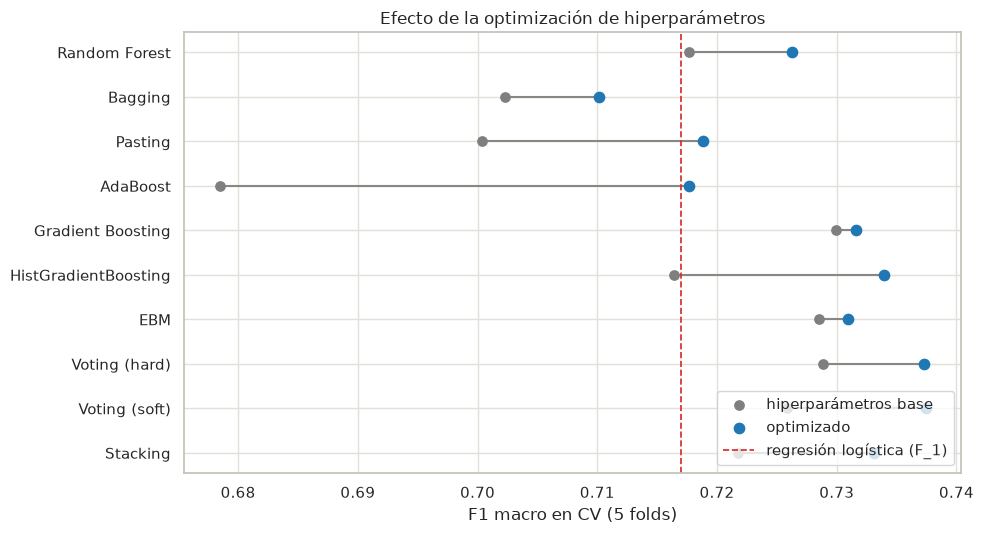

,Accuracy,Precision,Recall,F1,F1 ponderado,MCC,Kappa,ROC-AUC,Gap F1 (train−CV),Estimadores,Nº SV,Ajuste con todo Train (s)
Regresión Logística (F_1),0.7584 ± 0.0147,0.7203 ± 0.0201,0.7243 ± 0.0210,0.7170 ± 0.0192,0.7663 ± 0.0136,0.6178 ± 0.0227,0.6146 ± 0.0224,0.8913 ± 0.0104,0.0328,—,—,2.44
SVM RBF optimizado,0.7872 ± 0.0059,0.7496 ± 0.0142,0.7092 ± 0.0102,0.7217 ± 0.0108,0.7773 ± 0.0080,0.6483 ± 0.0105,0.6419 ± 0.0105,0.8630 ± 0.0090,0.0432,—,"1,636",0.18
Random Forest optimizado,0.7691 ± 0.0189,0.7308 ± 0.0213,0.7272 ± 0.0220,0.7262 ± 0.0221,0.7722 ± 0.0183,0.6275 ± 0.0296,0.6257 ± 0.0299,0.8892 ± 0.0110,0.2025,300,—,0.54
Bagging optimizado,0.7604 ± 0.0162,0.7175 ± 0.0190,0.7070 ± 0.0193,0.7101 ± 0.0195,0.7610 ± 0.0156,0.6099 ± 0.0251,0.6081 ± 0.0254,0.8807 ± 0.0104,0.1707,200,—,0.81
Pasting optimizado,0.7640 ± 0.0181,0.7239 ± 0.0201,0.7187 ± 0.0193,0.7189 ± 0.0200,0.7666 ± 0.0170,0.6185 ± 0.0274,0.6169 ± 0.0277,0.8824 ± 0.0106,0.1928,200,—,1.03
AdaBoost optimizado,0.7556 ± 0.0159,0.7272 ± 0.0190,0.7243 ± 0.0195,0.7177 ± 0.0187,0.7648 ± 0.0149,0.6143 ± 0.0245,0.6098 ± 0.0244,0.8830 ± 0.0099,0.0867,50,—,0.52
Gradient Boosting optimizado,0.7734 ± 0.0179,0.7337 ± 0.0180,0.7344 ± 0.0187,0.7316 ± 0.0191,0.7776 ± 0.0161,0.6358 ± 0.0267,0.6345 ± 0.0273,0.8944 ± 0.0116,0.1852,900,—,1.64
HistGradientBoosting optimizado,0.7785 ± 0.0181,0.7370 ± 0.0186,0.7348 ± 0.0182,0.7340 ± 0.0189,0.7812 ± 0.0162,0.6421 ± 0.0269,0.6410 ± 0.0273,0.8970 ± 0.0096,0.2133,300,—,0.36
EBM optimizado,0.7683 ± 0.0147,0.7340 ± 0.0133,0.7398 ± 0.0131,0.7309 ± 0.0139,0.7761 ± 0.0127,0.6343 ± 0.0200,0.6308 ± 0.0210,0.8936 ± 0.0097,0.0640,—,—,2.92
Voting (hard) optimizado,0.7793 ± 0.0175,0.7388 ± 0.0185,0.7395 ± 0.0184,0.7373 ± 0.0190,0.7826 ± 0.0156,0.6445 ± 0.0260,0.6434 ± 0.0264,—,0.1912,5,—,5.11


In [27]:
pares = [("Random Forest", "Random Forest optimizado"), ("Bagging (árboles)", "Bagging optimizado"),
         ("Pasting (árboles)", "Pasting optimizado"), ("AdaBoost", "AdaBoost optimizado"),
         ("Gradient Boosting (balanceado)", "Gradient Boosting optimizado"),
         ("HistGradientBoosting (balanceado)", "HistGradientBoosting optimizado"), ("EBM (10 interacciones)", "EBM optimizado"),
         ("Voting (hard)", "Voting (hard) optimizado"), ("Voting (soft)", "Voting (soft) optimizado"),
         ("Stacking (LR + SVM + RF → LR)", "Stacking optimizado")]
comp = pd.DataFrame({o.replace(" optimizado", ""): {
    "F1 base": resultados_cv[b]["F1_mean"], "F1 optimizado": resultados_cv[o]["F1_mean"],
    "Δ F1": resultados_cv[o]["F1_mean"] - resultados_cv[b]["F1_mean"],
    "std optimizado": resultados_cv[o]["F1_std"],
    "Gap base": resultados_cv[b]["gap_F1"], "Gap optimizado": resultados_cv[o]["gap_F1"],
    "Accuracy base → opt.": f"{resultados_cv[b]['Accuracy_mean']:.4f} → {resultados_cv[o]['Accuracy_mean']:.4f}",
    "MCC base → opt.": f"{resultados_cv[b]['MCC_mean']:.4f} → {resultados_cv[o]['MCC_mean']:.4f}",
    "ROC-AUC base → opt.": ("—" if np.isnan(resultados_cv[o]["ROC-AUC_mean"]) else
                            f"{resultados_cv[b]['ROC-AUC_mean']:.4f} → {resultados_cv[o]['ROC-AUC_mean']:.4f}")}
    for b, o in pares}).T
display(comp)
print(f"Referencia: {NOMBRE_LR} F1 macro en CV = {resultados_cv[NOMBRE_LR]['F1_mean']:.4f} ± {resultados_cv[NOMBRE_LR]['F1_std']:.4f}")
print("Resumen completo de los modelos optimizados (CV, 5 folds):")
display(tabla_resumen([NOMBRE_LR, "SVM RBF optimizado"] + [o for _, o in pares]))

fig, ax = plt.subplots(figsize=(10, 5.5))
y_pos = np.arange(len(pares))[::-1]
for yp, (b, o) in zip(y_pos, pares):
    ax.plot([resultados_cv[b]["F1_mean"], resultados_cv[o]["F1_mean"]], [yp, yp], color=COLOR_GRIS, lw=1.5, zorder=1)
ax.scatter([resultados_cv[b]["F1_mean"] for b, _ in pares], y_pos, color="tab:gray", s=45, label="hiperparámetros base", zorder=2)
ax.scatter([resultados_cv[o]["F1_mean"] for _, o in pares], y_pos, color="tab:blue", s=55, label="optimizado", zorder=3)
ax.axvline(resultados_cv[NOMBRE_LR]["F1_mean"], color="tab:red", ls="--", lw=1.2, label="regresión logística (F_1)")
ax.set_yticks(y_pos)
ax.set_yticklabels([o.replace(" optimizado", "") for _, o in pares])
ax.set_xlabel("F1 macro en CV (5 folds)")
ax.set_title("Efecto de la optimización de hiperparámetros")
ax.legend(loc="lower right")
plt.tight_layout()
guardar_fig("03_antes_vs_despues_optimizacion")
guardar_tabla(comp, "03_optimizacion_base_vs_optimizado")
guardar_tabla(tabla_resumen([NOMBRE_LR, "SVM RBF optimizado"] + [o for _, o in pares]), "03_modelos_optimizados_cv")

**Interpretación.**

- **La optimización mejora el F1 de CV de los 10 ensambles, pero poco:** +0.0127 en promedio, de +0.0016 (Gradient Boosting) a +0.0392 (AdaBoost), contra una desviación estándar entre folds de 0.014 a 0.022. Solo cinco ganan más de 0.01: AdaBoost (+0.039), Pasting (+0.018), HistGradientBoosting (+0.018), *Voting soft* (+0.012) y Stacking (+0.011). Gradient Boosting y el EBM ya venían bien configurados (+0.0016 y +0.0024): ahí no hay ganancia medible.
- **Casi todo lo que se gana en F1 se paga en sobreajuste.** El gap train − CV sube en 9 de los 10 modelos (en promedio de 0.099 a 0.163); la única excepción es HistGradientBoosting (0.282 a 0.213). Bagging pasó de 0.052 a 0.171, Pasting de 0.065 a 0.193 y *Voting soft* de 0.052 a 0.178. Buscar el mejor F1 de CV empuja hacia modelos más flexibles (árboles más profundos, menos regularización), que ganan unas milésimas en validación y se acercan a memorizar Train.
- **La Accuracy no es lo que se optimizó, y en los *voting* incluso baja** (*soft*: 0.7898 a 0.7858; *hard*: 0.7796 a 0.7793), mientras el *recall* macro del *soft* sube de 0.7149 a 0.7347. El ROC-AUC casi no cambia (+0.001 a +0.007, salvo AdaBoost, +0.029): la búsqueda mueve el punto de operación, no la calidad del ordenamiento.
- **Después de optimizar los ensambles quedan en 0.7101 a 0.7375 de F1 macro; los seis primeros, en un rango de 0.0066** (0.7309 a 0.7375), mucho menos que una desviación estándar. Por el criterio declarado de antemano gana *Voting soft*, pero supera a *Voting hard* por 0.0002. **Que sea el "mejor" es una decisión de procedimiento, no una evidencia de superioridad.** La regresión logística de referencia tiene 0.7170 ± 0.0192.

### Guardado para el notebook 04
Se guardan los modelos ajustados con todo Train, las predicciones *out-of-fold*, las métricas de CV y las búsquedas en `outputs/modelos/registro.joblib`,
y los mejores hiperparámetros de cada búsqueda en `outputs/tablas/03_mejores_hiperparametros.json`.

In [28]:
reg.guardar()

mejores = {n: {k.replace("model__", ""): v for k, v in s.best_params_.items()}
           for n, s in searches.items() if "mapa de calor" not in n}
with open(TABLAS / "03_mejores_hiperparametros.json", "w", encoding="utf-8") as f:
    json.dump(mejores, f, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o))

print(f"{len(modelos_ajustados)} modelos y {len(searches)} búsquedas guardados en outputs/modelos/registro.joblib")
print("Mejores hiperparámetros → outputs/tablas/03_mejores_hiperparametros.json")

31 modelos y 10 búsquedas guardados en outputs/modelos/registro.joblib
Mejores hiperparámetros → outputs/tablas/03_mejores_hiperparametros.json
